# MiTA 探针：用 top-k 共享读取解释 ViT —— 研究笔记本

**一句话：** 把注意力看成"每个图块是一个神经元"的快权重 MLP，再借用 MiTA 的规则，让每块区域只读 16 个神经元。"读了谁"就是解释图，而且这张图可以直接执行来检验。

这份笔记本汇总了：核心方法代码、指标定义、全部正式实验的核心结果和图表，以及运行前登记的预测与实际结果的对账。

| 部分 | 内容 | 数据来源 |
| --- | --- | --- |
| 0 | 环境与复现信息 | — |
| 1 | 研究问题与登记的预测 | `docs/decisions.md` |
| 2 | 方法：快权重视角、读取名单、解释图、执行模式 | **现场计算**（CPU，24 张随机抽取的 ImageNet-S 图） |
| 3 | 检验与指标：删图块与 SRG、同距离富集、其他指标、统计方法 | 现场计算 + 定义 |
| 4 | 实验总览 | 各运行文件夹的 `metadata.json` |
| 5 | 结果：RQ1–RQ4、E3–E8、健全性检验、成本 | `experiments/*/analysis_*.csv` 等结果表 |
| 6 | 逐层综合 | 同上 |
| 7 | 预测对账（由代码从结果表自动判定） | 同上 |
| 8 | 局限与下一步 | — |
| 9 | 复现命令与核心代码索引 | — |

**两类单元格：**

- **第 2–3 部分**在 CPU 上现场运行模型，说明方法和指标是怎么算的。这里只有 24 张图，数字只用来演示。
- **第 5–7 部分**只读取正式运行的结果文件（A100，float32，每项上千到上万张图），不重新计算。论文中的数字以这部分为准。

**运行要求：** 在仓库根目录或 `notebooks/` 文件夹中打开；需要安装 `requirements.txt` 中的依赖，并下载模型权重（`python scripts/download_models.py`）。在 4 核 CPU 上全部运行约 1–2 分钟。

## 0 环境与复现信息

In [1]:
import inspect
import json
import subprocess
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore', message='IProgress not found')  # tqdm in a kernel without ipywidgets

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
try:
    import mita_probe
except ImportError:  # not installed with pip: use the source tree
    sys.path.insert(0, str(ROOT / 'src'))
    import mita_probe

import matplotlib
import numpy as np
import pandas as pd
import timm
import torch
from IPython.display import display
from mita_probe.plotting import (BLUE, GRAY, INK, METHOD_COLORS, METHOD_LABELS, METHOD_STYLES, MODEL_LABELS,
                                 ORANGE, QUIET, band, interval_dots)

%matplotlib inline
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 100})
torch.manual_seed(0)
torch.set_grad_enabled(False)  # nothing below needs gradients
pd.options.display.float_format = '{:.3f}'.format
pd.options.display.max_colwidth = 120

EXP = ROOT / 'experiments'
V3 = '2026-10-29_v3_'
MODELS = ['deit', 'dino', 'deit_b']
DATASETS = ['imagenet_s', 'hard_imagenet', 'pet', 'imagenet']
MAIN = ['probe_mass', 'cls_attention', 'rollout', 'gae', 'gradcam', 'integrated_gradients', 'centre', 'random']
REFERENCES = {'centre', 'random', 'mask', 'mean_human'}
ANIMALS = ['Quadruped', 'Biped', 'Fish', 'Bird', 'Snake', 'Reptile']


def run(name):
    """Folder of one formal v3 run, e.g. run('e4_imagenet_s_deit')."""
    return EXP / f'{V3}{name}'


def label(method):
    return METHOD_LABELS.get(method, method)


def pick(frame, order):
    """Rows of `frame` in `order`, skipping methods a run did not compute."""
    return frame.loc[[m for m in order if m in frame.index]]


def ci(row, digits=3, scale=1):
    """'mean [low, high]' from a row with mean/low/high."""
    m, lo, hi = (row[c] * scale for c in ('mean', 'low', 'high'))
    return f'{m:.{digits}f} [{lo:.{digits}f}, {hi:.{digits}f}]'


commit = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=ROOT, capture_output=True, text=True).stdout
print(f'repository  {ROOT}')
print(f'git commit  {commit.strip()}')
print(f'python {sys.version.split()[0]} | torch {torch.__version__} | timm {timm.__version__} | '
      f'pandas {pd.__version__} | matplotlib {matplotlib.__version__}')
print(f'formal v3 runs found: {len(list(EXP.glob(V3 + "*")))}')

repository  /home/user/mita-vit
git commit  7557db8
python 3.13.17 | torch 2.7.0+cpu | timm 1.0.30 | pandas 3.1.0 | matplotlib 3.11.2
formal v3 runs found: 36


## 1 研究问题与登记的预测

**背景。** ViT 把 224×224 的图切成 196 个 16×16 的图块（token），再加一个用来分类的 CLS token。常用的解释方法给每个图块打一个"重要性"分数，画成热图。它们有两个常见问题：

- **不忠实**：热图看起来合理，但模型其实不依赖这些地方。
- **中心偏差**：照片里的物体通常在中间，所以一张"永远只亮中间"的图也能拿高分。

**我们的做法。** 一层注意力和一个两层 MLP 形式相同，每个 token 就是一个"神经元"，而且对应图上一个固定位置。我们用 MiTA 的 top-k 共享读取规则，从**未改动**的 ViT 中读出"每块区域读了哪 16 个神经元"，把它当作解释，并用统一的检验和现有方法比较。

| 研究问题 | 问题 | 主要实验 |
| --- | --- | --- |
| 前提 | 深层的 token 还代表原来的图块位置吗？ | E3 |
| RQ1 忠实 | 只读少数共享神经元，能否复现一层注意力？ | E1 解剖 |
| RQ2 结构 | 各层、各模型怎样使用神经元？ | E1 逐层、名单并集 |
| RQ3 常识 | 模型依赖的神经元是否就是物体和关键部件，而不只是画面中间？ | E4 合理性、E5 移位、E6 配对删除、E7 人类图、E8 部件 |
| RQ4 对比 | 在同一套检验下，探针和现有解释方法相比如何？ | E4 忠实性、健全性检验、成本 |

**新意的边界（决策 B05）。** 快权重视角、读取名单可视化、"深层集中在少数 token"都已出现在 MiTA 论文和更早的工作中，不算本研究的新意。本研究的新意是**检验方式**：执行式的充分性检验、带中心配对的必要性检验、扣除中心偏差的合理性指标，以及在同一套检验下与现有方法比较。

**运行前登记。** 主定义（第 9–12 层、m = 16 块区域、每块读 k = 16 个）、所有指标、判定标准和预测，都在正式运行前写入 `docs/decisions.md`（B05–B19）。第 7 部分按原标准逐项对账。

## 2 方法（现场计算）

### 2.0 载入模型和随机样例

用 DeiT-S 和 24 张 ImageNet-S 验证图。这 24 张是定性图实验按 seed 0 随机抽取的（决策 B16，不挑图），图片与当时 GPU 运行保存的结果一起存放在 `gallery_imagenet_s.npz` 中。

In [2]:
from timm.data import resolve_model_data_config

from mita_probe.models import data_reference, load_model

model = load_model('deit')
gallery = np.load(run('gallery_deit') / 'gallery_imagenet_s.npz')
config = resolve_model_data_config(data_reference(model))
mean, std = (torch.tensor(config[key])[:, None, None] for key in ('mean', 'std'))
images = (torch.from_numpy(gallery['rgb']).permute(0, 3, 1, 2).float() / 255 - mean) / std
logits = model(images)
grid = model.patch_embed.grid_size
scale = model.blocks[0].attn.scale
print(f'{len(images)} images, input {tuple(images.shape[1:])}, patch grid {grid}, '
      f'{len(model.blocks)} layers x {model.blocks[0].attn.num_heads} heads')
print(f'top-1 equals the stored GPU run on {(logits.argmax(-1).numpy() == gallery["top1"]).mean():.0%} of images')

24 images, input (3, 224, 224), patch grid (14, 14), 12 layers x 6 heads
top-1 equals the stored GPU run on 100% of images


### 2.1 注意力就是一个"快权重 MLP"

对第 $i$ 个 token 的 query $q_i$，一层注意力（一个头）的输出是

$$\mathrm{Attn}(q_i) = \sum_{j=1}^{197} \underbrace{\mathrm{softmax}_j\!\left(q_i^\top k_j / \sqrt{d}\right)}_{\text{神经元 } j \text{ 的激活 } h_j}\; v_j .$$

把它和两层 MLP $y = W_2^\top\, \sigma(W_1 x)$ 对照：

| MLP | 注意力 |
| --- | --- |
| 输入 $x$ | query $q_i$ |
| 第一层权重 $W_1$ 的第 $j$ 行 | key $k_j$ |
| 激活函数 $\sigma$ | softmax |
| 第二层权重 $W_2$ 的第 $j$ 行 | value $v_j$ |

权重来自这张图本身，每张图都不同，所以叫"快权重"。关键在于：**神经元 $j$ 对应图上的第 $j$ 个图块**，所以"这一层用了哪些神经元"可以直接画在图上。

下面在第 10 层、第 1 个头上验证两种写法的输出相同，并把一个 query 的 197 个神经元激活画成 14×14 的图。

attention output == fast-weight MLP output: True
hidden neurons: 197 (CLS + 196 patches); CLS activation 0.060; top-16 patch neurons hold 0.50 of the mass


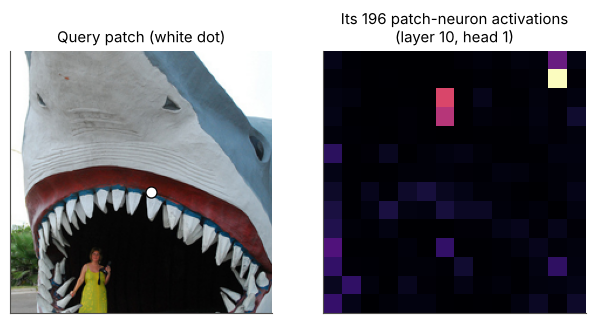

In [3]:
from mita_probe.probe.execute import split_qkv

LAYER, HEAD, IMAGE, PATCH = 10, 0, 0, 7 * 14 + 7  # a patch near the centre of image 0
inputs = {}
hook = model.blocks[LAYER - 1].attn.register_forward_pre_hook(lambda module, args: inputs.__setitem__('x', args[0]))
model(images[IMAGE:IMAGE + 1])
hook.remove()
q, k, v = split_qkv(model.blocks[LAYER - 1].attn, inputs['x'])  # [1, heads, 197, 64]

attention_out = ((q * scale) @ k.transpose(-2, -1)).softmax(-1) @ v  # attention view
W1, W2, x = k[0, HEAD], v[0, HEAD], q[0, HEAD, 1 + PATCH]            # MLP view: 197 hidden neurons
hidden = torch.softmax(W1 @ x * scale, -1)
mlp_out = hidden @ W2
print('attention output == fast-weight MLP output:', torch.allclose(mlp_out, attention_out[0, HEAD, 1 + PATCH], atol=1e-5))
print(f'hidden neurons: {hidden.numel()} (CLS + 196 patches); CLS activation {hidden[0]:.3f}; '
      f'top-16 patch neurons hold {hidden[1:].topk(16).values.sum():.2f} of the mass')

fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.2))
axes[0].imshow(gallery['rgb'][IMAGE])
axes[0].plot(*(np.array(divmod(PATCH, 14))[::-1] * 16 + 8), 'o', color='white', mec=INK, ms=8)
axes[0].set_title('Query patch (white dot)')
axes[1].imshow(hidden[1:].reshape(14, 14), cmap='magma')
axes[1].set_title(f'Its 196 patch-neuron activations\n(layer {LAYER}, head {HEAD + 1})')
for ax in axes:
    ax.set(xticks=[], yticks=[])
    ax.grid(False)
plt.tight_layout()

### 2.2 读取名单：MiTA 的 top-k 共享读取

规则（每层、每个头分别做）：

1. 把 14×14 的图块按位置分成 4×4 = 16 块区域；
2. 区域内所有 query 的平均值作为这块区域的"代表"（landmark）；
3. 代表给全部 197 个 key 打分，分数最高的 k = 16 个 token 就是这块区域的**读取名单**；区域内的每个 query 都只读这份名单；
4. CLS 用自己的 query 选自己的 16 个。

下面先用约 10 行代码写一个参考实现，再检查它和项目代码 `build_pattern` 的结果完全相同。

In [4]:
from mita_probe.probe import build_pattern, capture_qk


def reading_sets(q, k, scale, side=4, k_top=16, grid=14):
    """Reference: each region's mean patch query (adaptive-pooling window) scores every key; keep the top-k."""
    batch, heads, _, dim = q.shape
    patches = q[:, :, 1:].reshape(batch, heads, grid, grid, dim)
    edges = [(i * grid // side, -(-(i + 1) * grid // side)) for i in range(side)]
    landmarks = torch.stack([patches[:, :, r0:r1, c0:c1].mean((2, 3)) for r0, r1 in edges for c0, c1 in edges], 2)
    return ((landmarks * scale) @ k.transpose(-2, -1)).topk(k_top, -1).indices  # [batch, heads, regions, k]


with capture_qk(model) as qk:  # Q and K of every layer from one ordinary forward pass
    model(images)
pattern, _ = build_pattern(*qk[LAYER], m_side=4, k_top=16, scale=scale, grid=grid)
mine = reading_sets(*qk[LAYER], scale)
same = torch.equal(mine.sort(-1).values, pattern.readsets.sort(-1).values)
print(f'reading sets, layer {LAYER}: reference == package build_pattern: {same}')
print(f'shape {tuple(pattern.readsets.shape)} = [images, heads, regions, k]; CLS set {tuple(pattern.cls_set.shape)}')

reading sets, layer 10: reference == package build_pattern: True
shape (24, 6, 16, 16) = [images, heads, regions, k]; CLS set (24, 6, 16)


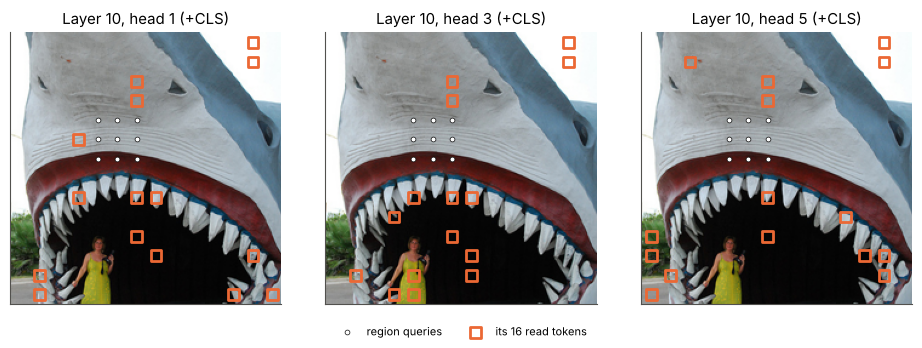

In [5]:
REGION = 5  # second row, second column of the 4x4 regions
rows, cols = np.divmod(np.arange(196), 14)
region_of = (rows * 4 // 14) * 4 + cols * 4 // 14  # spatial routing: which region each patch query belongs to

fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.3))
for ax, head in zip(axes, [0, 2, 4]):
    read = pattern.readsets[IMAGE, head, REGION].numpy()
    ax.imshow(gallery['rgb'][IMAGE])
    member = region_of == REGION
    ax.scatter(cols[member] * 16 + 8, rows[member] * 16 + 8, s=12, color='white', edgecolor=INK, linewidths=.5, label='region queries')
    patch = read[read > 0] - 1  # token 0 is CLS
    ax.scatter(patch % 14 * 16 + 8, patch // 14 * 16 + 8, s=60, marker='s', facecolor='none', edgecolor=ORANGE,
               lw=2, label='its 16 read tokens')
    ax.set(title=f'Layer {LAYER}, head {head + 1}' + (' (+CLS)' if (read == 0).any() else ''), xticks=[], yticks=[])
    ax.grid(False)
plt.tight_layout(rect=(0, .08, 1, 1))
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=2, fontsize=8)

### 2.3 解释图：探针的主定义 `probe_mass`

只在读取名单内计算注意力，统计每个图块（神经元）一共收到多少注意力，再把第 9–12 层、所有头、所有 query 加起来：

$$s_j = \sum_{\ell=9}^{12} \sum_{h} \sum_{i} \frac{\exp(q_i^\top k_j/\sqrt d)\;[\,j \in S^{\ell,h}_{r(i)}\,]}{\sum_{j' \in S^{\ell,h}_{r(i)}} \exp(q_i^\top k_{j'}/\sqrt d)}$$

其中 $S_{r(i)}$ 是 query $i$ 所在区域的读取名单。它**不训练、不用梯度、不需要知道类别**，成本约等于一次前向计算。

下面用参考实现计算，检查它和项目代码 `explain.probe` 一致，再和当时 GPU 运行保存的图比较。

In [6]:
from mita_probe import explain
from mita_probe.probe import resolve

MAIN_BUDGET = dict(m_side=4, k=16, routing='spatial', cls='own', scoring='query', summary_scale='mita')
SPEC = resolve({'mode': 'L3'}, MAIN_BUDGET)  # the registered main definition
PROBE_LAYERS = [9, 10, 11, 12]


def probe_mass(qk, layers=PROBE_LAYERS, side=4, k_top=16):
    """Reference: attention mass each patch receives when every query may read only its region's set."""
    total = 0
    for layer in layers:
        q, k = qk[layer]
        sets = reading_sets(q, k, scale, side, k_top)
        cls_set = ((q[:, :, :1] * scale) @ k.transpose(-2, -1)).topk(k_top, -1).indices
        allowed = torch.zeros(*sets.shape[:3], q.shape[2], dtype=torch.bool).scatter_(-1, sets, True)
        cls_row = torch.zeros_like(allowed[:, :, :1]).scatter_(-1, cls_set, True)
        mask = torch.cat([cls_row, allowed[:, :, torch.from_numpy(region_of)]], 2)  # [batch, heads, 197, 197]
        probs = ((q * scale) @ k.transpose(-2, -1)).masked_fill(~mask, -torch.inf).softmax(-1)
        total = total + probs.sum((1, 2))
    return total[:, 1:]


probe_map = probe_mass(qk)
package_map = explain.probe(model, images, SPEC, PROBE_LAYERS)
stored = torch.from_numpy(gallery['probe_mass'])
print('reference == package explain.probe:', torch.allclose(probe_map, package_map, rtol=1e-4, atol=1e-3))
print(f'correlation with the map saved by the GPU run: {np.corrcoef(probe_map.ravel(), stored.ravel())[0, 1]:.5f} '
      '(images re-quantised to uint8 for storage, so not bit-identical)')
top = lambda m: set(m.topk(20).indices.tolist())
print(f'top-20 patches shared with the stored map: '
      f'{np.mean([len(top(a) & top(b)) / 20 for a, b in zip(probe_map, stored)]):.1%}')

reference == package explain.probe: True
correlation with the map saved by the GPU run: 0.99996 (images re-quantised to uint8 for storage, so not bit-identical)
top-20 patches shared with the stored map: 99.8%


### 2.4 和其他方法的图放在一起

其他方法的图来自当时 GPU 运行保存的结果（GAE、Grad-CAM、IG 需要梯度，这里不现场重算）。白线是真实物体的轮廓。

- **CLS 注意力**：分类用的 CLS token 对各图块的注意力。
- **Rollout**：把各层注意力连乘（Abnar & Zuidema 2020）。
- **GAE**：注意力 × 梯度逐层传递（Chefer 等 2021），针对预测的类别。
- **Grad-CAM**、**Integrated Gradients (IG)**：基于梯度。

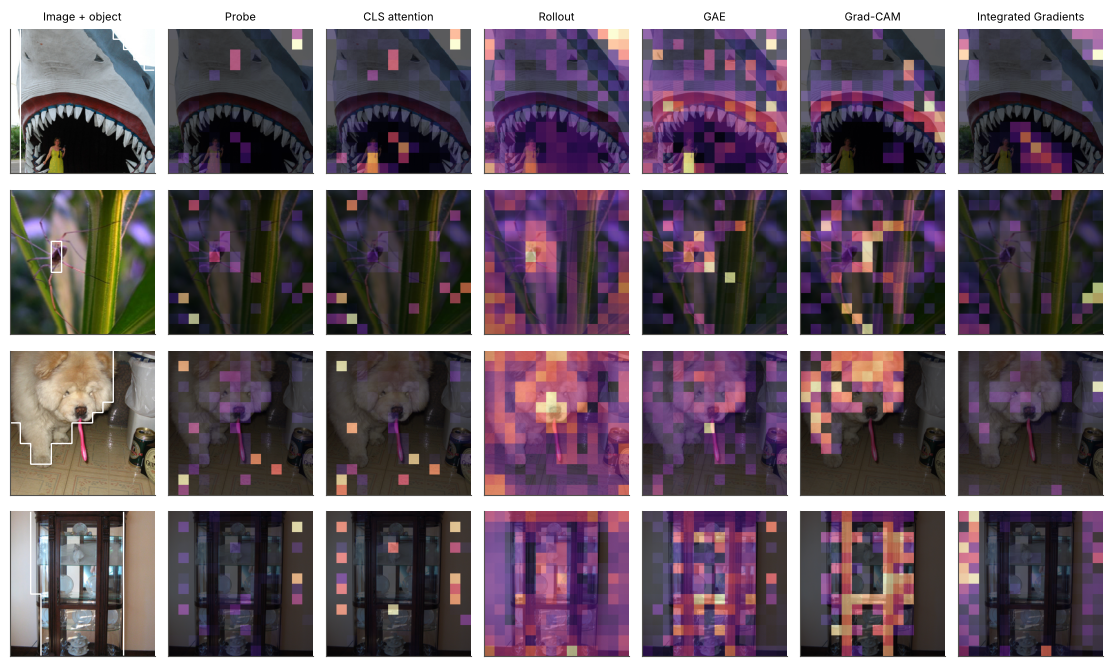

In [7]:
SHOW = [0, 3, 6, 9]
methods = ['probe_mass', 'cls_attention', 'rollout', 'gae', 'gradcam', 'integrated_gradients']
fig, axes = plt.subplots(len(SHOW), len(methods) + 1, figsize=(1.6 * (len(methods) + 1), 1.7 * len(SHOW)))
for row, n in zip(axes, SHOW):
    row[0].imshow(gallery['rgb'][n])
    row[0].contour(np.kron(gallery['truth'][n].reshape(14, 14), np.ones((16, 16))), [.5], colors='white',
                   linewidths=1)
    for ax, method in zip(row[1:], methods):
        heat = probe_map[n].numpy() if method == 'probe_mass' else gallery[method][n]
        ax.imshow(gallery['rgb'][n])
        ax.imshow(np.kron(heat.reshape(14, 14), np.ones((16, 16))), cmap='magma', alpha=.65)
    for ax in row:
        ax.set(xticks=[], yticks=[])
        ax.grid(False)
for ax, title in zip(axes[0], ['Image + object'] + [label(m).replace(' (ours)', '') for m in methods]):
    ax.set_title(title, fontsize=8)
plt.tight_layout()

### 2.5 逐层看：每一层的读取

把同样的计算只放在一层上，就得到这一层的解释图。下面是 3 张图在第 1–12 层的读取（取自保存的结果）。浅层是局部纹理；中层集中到物体上；DeiT-S 的最后两层又散到背景上的少数几个图块。

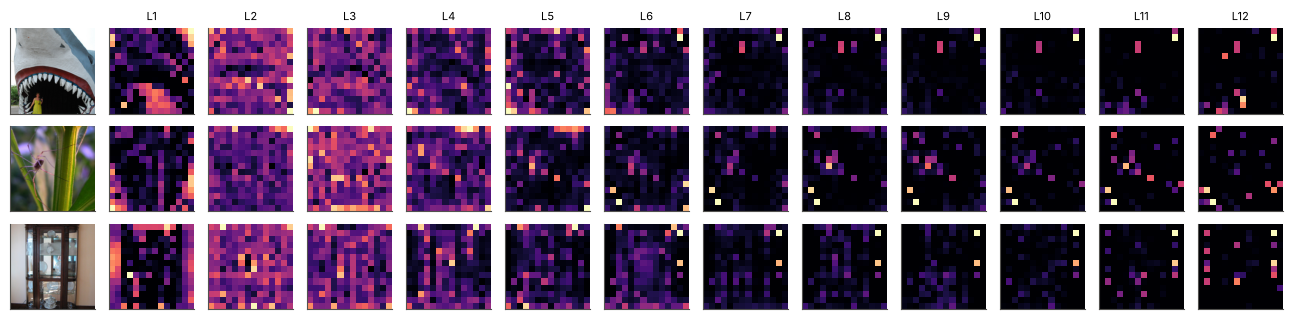

In [8]:
fig, axes = plt.subplots(3, 13, figsize=(13, 3.3))
for row, n in zip(axes, [0, 3, 9]):
    row[0].imshow(gallery['rgb'][n])
    for layer in range(12):
        row[layer + 1].imshow(gallery['probe_layers'][n, layer].reshape(14, 14), cmap='magma')
    for ax in row:
        ax.set(xticks=[], yticks=[])
        ax.grid(False)
for layer in range(12):
    axes[0, layer + 1].set_title(f'L{layer + 1}', fontsize=8)
plt.tight_layout()

### 2.6 执行模式：只按名单计算，模型答案还对吗？

这是探针和其他解释方法最不同的地方：它的解释可以直接**执行**。让 12 层都只按读取名单计算注意力，看 top-1 是否和原模型相同；对照是同样大小的随机名单（`rand`）。这里只有 24 张图，正式结果（5,000 张）见 5.1。

In [9]:
from mita_probe.probe import execute, make_plan

rows_ = []
for k_top in [4, 8, 16, 32, 64, 128]:
    for mode in ['L3', 'rand']:
        spec = resolve({'mode': mode, 'k': k_top, 'seed': 0}, MAIN_BUDGET)
        plans = {layer: make_plan(spec, *qk[layer], scale, grid, layer=layer) for layer in range(1, 13)}
        with execute(model, plans):
            executed = model(images)
        rows_.append(dict(k=k_top, sets='probe' if mode == 'L3' else 'random',
                          agree=(executed.argmax(-1) == logits.argmax(-1)).float().mean().item()))
demo = pd.DataFrame(rows_).pivot(index='sets', columns='k', values='agree')
print('Top-1 agreement with the original model, all 12 layers executed (24 demo images):')
display((demo * 100).round(0).astype(int).astype(str) + '%')

Top-1 agreement with the original model, all 12 layers executed (24 demo images):


k,4,8,16,32,64,128
sets,,,,,,
probe,29%,67%,71%,83%,96%,96%
random,0%,4%,8%,17%,62%,88%


## 3 检验与指标

### 3.1 忠实性：删图块，主指标 SRG

**删图块**的意思是：这些图块在所有层都不能被读取。实现上直接把它们从序列中删掉（决策 B17），这和"在每层注意力中屏蔽它们"在数值上相同。下面先验证这一点。

**SRG**（主忠实性指标，决策 B11）：按解释图给图块排序，

- 先删最**不**重要的（least relevant first）：解释准的话，答案应一直保持；
- 先删最重要的（most relevant first）：解释准的话，答案应很快变掉。

横轴是删除比例（0、1、2、4、…、147 个，除以 196），纵轴是与原 top-1 一致的比例；删 0 个时记为 1。两条曲线下面积之差就是 SRG，越大越忠实，随机打分约为 0。

In [10]:
from mita_probe.faithfulness import curve, keep_mask, rank, run_kept
from mita_probe.probe import Plan

# Removing tokens: dropping them after the positional embedding == masking them in every layer's attention.
order = rank(probe_map[:2], torch.Generator().manual_seed(0))
keep = keep_mask(order, torch.tensor([40, 120]))  # keep 40 and 120 patches (+ CLS)
mask = keep[:, None, None, :].expand(2, model.blocks[0].attn.num_heads, 197, 197)
with execute(model, {layer: Plan(token_mask=mask) for layer in range(1, 13)}):
    masked = model(images[:2])
print(f'max |logit difference|, dropping vs masking: {(run_kept(model, images[:2], keep) - masked).abs().max():.1e}')

max |logit difference|, dropping vs masking: 1.8e-05


Demo SRG on 24 images: {'Probe (ours)': 0.181, 'GAE': 0.343, 'Centre (reference)': 0.085, 'Random (reference)': -0.002}


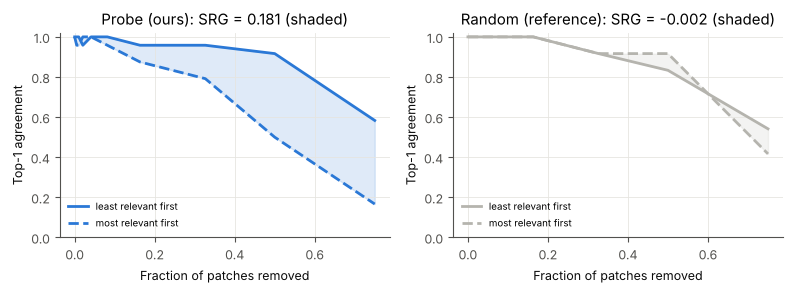

In [11]:
from mita_probe.stats import trapezoid

BUDGETS = [1, 2, 4, 8, 16, 32, 64, 98, 147]  # configs/explanations.yaml
x_axis = np.array([0] + BUDGETS) / 196


def srg_curves(scores, generator):
    """Per-image agreement curves (least- and most-relevant-first removal) and SRG."""
    order = rank(scores, generator)
    out = {}
    for condition in ['drop_bottom', 'drop_top']:
        result = curve(model, images, logits, order, BUDGETS, condition)
        out[condition] = np.stack([np.ones(len(images))] + [result[b]['agree'].numpy() for b in BUDGETS], 1)
    return out, trapezoid(x_axis, out['drop_bottom']) - trapezoid(x_axis, out['drop_top'])


demo_maps = {'probe_mass': probe_map, 'gae': torch.from_numpy(gallery['gae']),
             'centre': torch.from_numpy(gallery['centre']), 'random': torch.from_numpy(gallery['random'])}
generator = torch.Generator().manual_seed(0)
demo_curves, demo_srg = {}, {}
for name, scores in demo_maps.items():
    demo_curves[name], demo_srg[name] = srg_curves(scores, generator)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, name in zip(axes, ['probe_mass', 'random']):
    low, high = demo_curves[name]['drop_bottom'].mean(0), demo_curves[name]['drop_top'].mean(0)
    ax.plot(x_axis, low, color=METHOD_COLORS[name], lw=2, label='least relevant first')
    ax.plot(x_axis, high, '--', color=METHOD_COLORS[name], lw=2, label='most relevant first')
    ax.fill_between(x_axis, high, low, color=METHOD_COLORS[name], alpha=.15)
    ax.set(title=f'{label(name)}: SRG = {demo_srg[name].mean():.3f} (shaded)', xlabel='Fraction of patches removed',
           ylabel='Top-1 agreement', ylim=(0, 1.02))
    ax.legend(fontsize=7)
plt.tight_layout()
print('Demo SRG on 24 images:', {label(k): round(float(v.mean()), 3) for k, v in demo_srg.items()})

### 3.2 合理性：同距离富集（扣除中心偏差）

**问题**：物体通常在中间，所以"偏向物体"可能只是"偏向中间"。

**做法**（主合理性指标，决策 B11）：按离画面中心的距离把图块分成一圈一圈。只在**同一圈内**比较：解释图选中的图块里物体比例，减去这一圈的平均物体比例。每张图取按选中数加权的平均（选中个数 = 物体图块数）。

- 0 = 和"只看中间"一样；
- 大于 0 = 在同样离中心的距离上，也更偏向物体。

中心高斯参照在每一圈内是常数，所以它的富集约为 0；真实物体掩码给出上限。

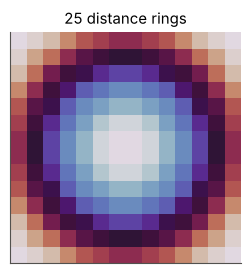

Demo on 24 images (formal results in 5.5):


,object mass share,same-ring enrichment
Probe (ours),0.441,0.120
CLS attention,0.327,0.072
GAE,0.554,0.190
Centre (reference),0.520,-0.008
Object mask (reference),1.000,0.446


In [12]:
from mita_probe.interventions import centre_rings
from mita_probe.plausibility import measures as plausibility

rings = centre_rings()[1:].numpy()
foreground = torch.from_numpy(gallery['truth'])
valid = torch.ones_like(foreground)
demo_plaus = {}
for name in ['probe_mass', 'cls_attention', 'gae', 'centre']:
    scores = probe_map if name == 'probe_mass' else torch.from_numpy(gallery[name])
    result = plausibility(scores, foreground, valid, foreground.roll(1, 0), generator=torch.Generator().manual_seed(0))
    demo_plaus[label(name)] = {'object mass share': np.nanmean(result['mass']),
                               'same-ring enrichment': np.nanmean(result['enrichment'])}
mask_result = plausibility(foreground.float(), foreground, valid, foreground.roll(1, 0),
                           generator=torch.Generator().manual_seed(0))
demo_plaus[label('mask')] = {'object mass share': np.nanmean(mask_result['mass']),
                             'same-ring enrichment': np.nanmean(mask_result['enrichment'])}

fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(rings.reshape(14, 14), cmap='twilight')
ax.set(title=f'{len(np.unique(rings))} distance rings', xticks=[], yticks=[])
ax.grid(False)
plt.show()
print('Demo on 24 images (formal results in 5.5):')
display(pd.DataFrame(demo_plaus).T)

### 3.3 其他指标一览

| 实验 | 指标 | 定义 | 怎么读 |
| --- | --- | --- | --- |
| E4 | 固定预算一致率 | 每种方法只保留它排在前面的 K 个图块，K = 探针第 9–12 层名单涉及的图块数 | 越高越好 |
| E4 | SaCo（Wu 等 2024） | 按排名分 10 组，分数高的组删掉后伤害是否也更大，成对比较 | −1 到 1，越大越好 |
| E5 | 物体质量下降 | 同一物体从居中裁剪移到四角后，解释图落在物体上的比例下降多少 | 越小越说明跟着物体走 |
| E6 | 删物体 − 删同距离 | 从读取名单删物体 token，对比删同样数量、离中心同距离的非物体 token | 小于 0 = 物体本身重要；"剩余比例" = 排除中心后物体效应还剩多少 |
| E7 | 图片特异 Spearman | 与本图人类图的相关 − 与另一张图人类图的相关（Harmonization 几何） | 中心参照为 0，越大越好 |
| E8 | 头部富集 | 解释图分给头的比例 ÷ 头占物体面积的比例 | 1 = 不偏不倚 |
| E8 | 部件依赖 | 从一个部件随机删 4 个图块（所有层不读），原 top-1 对数概率下降（种子 0–4 平均） | 越大越依赖 |
| E8 | 对得上比例 | 解释图最偏爱的部件，是否就是删除伤害最大的部件 | 瞎猜约 40% |
| 健全性 | Spearman 中位数 | 从输出端逐级重新初始化权重后，新图与原图的相关（Adebayo 等 2018） | 全部 12 块随机化后 < 0.5 为通过 |

### 3.4 统计方法

先按图片求每个量（随机对照先对种子 0–4 取平均），再**按图片配对 bootstrap 1,000 次（seed 0）**求 95% 区间（决策 B10）。"主比较"是探针减对手的配对差：区间全在 0 以上记为 `higher`，全在 0 以下记为 `lower`，否则为 `uncertain`。下面用 24 张演示图的 SRG 做一个例子。

In [13]:
from mita_probe.stats import paired, resample_indices

per_image = pd.DataFrame(demo_srg)
draws = resample_indices(len(per_image))  # 1,000 resamples, seed 0
display(pd.DataFrame(paired(per_image, 'probe_mass', ['random', 'centre', 'gae'], draws, measure='srg_agree (demo)')))

,measure,base,other,difference,low,high,verdict
0,srg_agree (demo),probe_mass,random,0.183,0.101,0.265,higher
1,srg_agree (demo),probe_mass,centre,0.096,-0.033,0.215,uncertain
2,srg_agree (demo),probe_mass,gae,-0.162,-0.268,-0.059,lower


## 4 实验总览

每次正式运行一个文件夹，保存配置、日志、结果表和当时的 git commit；源代码有未提交改动时程序拒绝运行。下表从各运行的 `metadata.json` 读取。

In [14]:
EXPERIMENTS = {'deit_b': 'E1 anatomy, DeiT-B (DeiT-S/DINO: 2026-10-28_v2_*)', 'e3': 'E3 token identity',
               'e4': 'E4 faithfulness + plausibility',
               'e5': 'E5 shifted crops', 'e6': 'E6 centre-matched deletion', 'e7': 'E7 ClickMe human maps',
               'e8': 'E8 PartImageNet parts', 'sanity': 'Sanity check', 'gallery': 'Qualitative gallery'}
rows_ = []
for folder in sorted(EXP.glob(V3 + '*')):
    meta_file = folder / 'metadata.json'
    if not meta_file.exists():
        continue
    meta = json.loads(meta_file.read_text())
    key = folder.name.removeprefix(V3)
    rows_.append(dict(run=key, experiment=next((v for k, v in EXPERIMENTS.items() if key.startswith(k)), 'other'),
                      model=meta.get('model', 'all'), dataset=meta.get('dataset', ''),
                      images=meta.get('images', ''), device=meta.get('device', ''), commit=meta['git_commit'][:7]))
overview = pd.DataFrame(rows_).sort_values(['experiment', 'run'])
print(f"{len(overview)} formal runs; devices: {', '.join(overview.device.unique())}")
display(overview.drop(columns='device').set_index('run'))

33 formal runs; devices: NVIDIA A100-SXM4-80GB


,experiment,model,dataset,images,commit
run,,,,,
deit_b_repro,"E1 anatomy, DeiT-B (DeiT-S/DINO: 2026-10-28_v2_*)",deit_b,,,08367cc
deit_b_rq1,"E1 anatomy, DeiT-B (DeiT-S/DINO: 2026-10-28_v2_*)",deit_b,,,08367cc
deit_b_rq2,"E1 anatomy, DeiT-B (DeiT-S/DINO: 2026-10-28_v2_*)",deit_b,,,08367cc
e3_identity_deit,E3 token identity,deit,,,08367cc
e3_identity_deit_b,E3 token identity,deit_b,,,2f5aac9
e3_identity_dino,E3 token identity,dino,,,08367cc
e4_hard_imagenet_deit,E4 faithfulness + plausibility,deit,hard_imagenet,750,08367cc
e4_hard_imagenet_deit_b,E4 faithfulness + plausibility,deit_b,hard_imagenet,750,2f5aac9
e4_hard_imagenet_dino,E4 faithfulness + plausibility,dino,hard_imagenet,750,08367cc


## 5 结果（只读取正式结果文件）

### 5.1 RQ1、RQ2：只读少数神经元能复现模型吗？

**做法**：执行模式。12 层同时只按读取名单计算，看 top-1 与原模型一致的比例（ImageNet 验证子集 5,000 张，seed 0）。

DeiT-S, all 12 layers executed, top-1 agreement (5,000 images):


k,4,8,16,32,64,128
method,,,,,,
probe sets (4x4 regions),25.300,48.600,69.400,81.200,88.600,95.100
probe sets (k-means regions),19.200,46.700,71.400,83.900,90.000,96.400
random sets (5 seeds),0.500,2.100,9.500,30.300,60.100,84.400


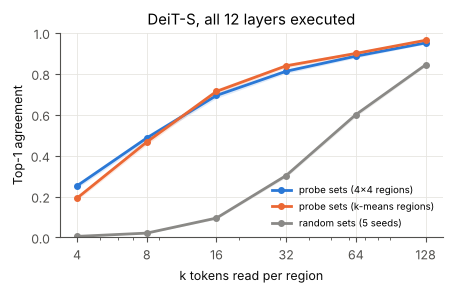

In [15]:
sweep = pd.read_csv(EXP / '2026-10-27_rq1_colab_combined' / 'summary.csv')
names = {'grid': 'probe sets (4x4 regions)', 'kmeans': 'probe sets (k-means regions)', 'random': 'random sets (5 seeds)'}
table = sweep.pivot(index='method', columns='k', values='agree').loc[list(names)].rename(index=names)
print('DeiT-S, all 12 layers executed, top-1 agreement (5,000 images):')
display((table * 100).round(1))

fig, ax = plt.subplots(figsize=(4.6, 3))
for method, color in [('grid', BLUE), ('kmeans', ORANGE), ('random', GRAY)]:
    part = sweep.query('method == @method').sort_values('k')
    ax.plot(part.k, part.agree, 'o-', color=color, lw=2, ms=4, label=names[method])
    ax.fill_between(part.k, part.agree_ci_low, part.agree_ci_high, color=color, alpha=.15, lw=0)
ax.set(xscale='log', xticks=part.k, xticklabels=part.k, xlabel='k tokens read per region',
       ylabel='Top-1 agreement', title='DeiT-S, all 12 layers executed', ylim=(0, 1))
ax.legend(fontsize=7)
plt.tight_layout()

**三个模型在主预算下（m = 16、k = 16，12 层同时执行）**，以及几种对照名单：

model,DeiT-S,DINO ViT-S,DeiT-B
quantity,,,
random sets,9.200,4.200,29.500
random sets + region summaries,32.300,17.300,60.500
"probe sets (strict, main)",71.500,61.500,82.800
probe sets + region summaries (MiTA),78.400,73.700,85.200
region summaries only,8.200,3.000,13.600
each query picks its own 16,76.500,67.800,88.100
each query picks its own 32,86.700,75.100,92.700


DeiT-S: one layer executed with probe sets keeps 91.7%-96.0% of top-1 predictions
DINO ViT-S: one layer executed with probe sets keeps 76.7%-94.9% of top-1 predictions
DeiT-B: one layer executed with probe sets keeps 95.1%-97.1% of top-1 predictions


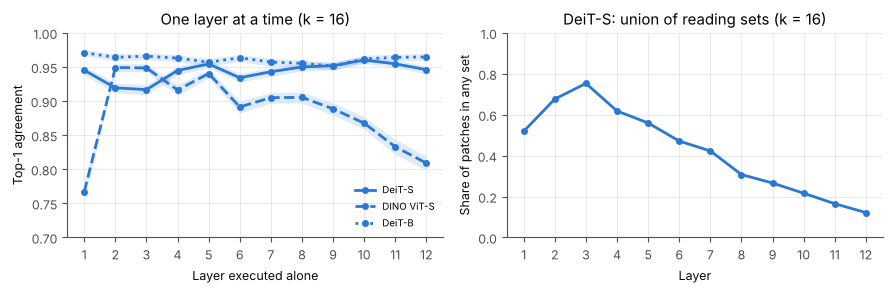

In [16]:
rq2 = pd.read_csv(run('deit_b_analysis') / 'compare_rq2_anatomy_all_layers.csv')
settings = {'rand': 'random sets', 'randC': 'random sets + region summaries', 'L3': 'probe sets (strict, main)',
            'L4': 'probe sets + region summaries (MiTA)', 'L2': 'region summaries only',
            'L1_k16': 'each query picks its own 16', 'L1_k32': 'each query picks its own 32'}
rq2_table = (rq2[rq2.quantity.isin(settings)].pivot(index='quantity', columns='model', values='mean')
             .loc[list(settings), MODELS].rename(index=settings, columns=MODEL_LABELS))
display((rq2_table * 100).round(1))

single = {'deit': EXP / '2026-10-28_v2_analysis', 'dino': EXP / '2026-10-28_v2_dino_analysis',
          'deit_b': run('deit_b_analysis')}
coverage = pd.read_csv(EXP / '2026-10-28_v2_analysis' / 'rq1_coverage.csv').query("measure == 'L3_spatial_k16_union'")
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for (model_name, folder), style in zip(single.items(), ['-', '--', ':']):
    layers = pd.read_csv(folder / 'rq1_anatomy.csv').query("quantity == 'L3'").astype({'layer': int}).sort_values('layer')
    band(axes[0], layers.layer, layers, BLUE, label=MODEL_LABELS[model_name], style=style)
    print(f'{MODEL_LABELS[model_name]}: one layer executed with probe sets keeps '
          f'{layers["mean"].min():.1%}-{layers["mean"].max():.1%} of top-1 predictions')
axes[0].set(xlabel='Layer executed alone', ylabel='Top-1 agreement', title='One layer at a time (k = 16)',
            xticks=range(1, 13), ylim=(0.7, 1))
axes[0].legend(fontsize=7)
coverage = coverage.astype({'layer': int}).sort_values('layer')
band(axes[1], coverage.layer, coverage, BLUE)
axes[1].set(xlabel='Layer', ylabel='Share of patches in any set', title='DeiT-S: union of reading sets (k = 16)',
            xticks=range(1, 13), ylim=(0, 1))
plt.tight_layout()

**解读：**

- **单层替换**时，探针名单几乎完全复现模型：DeiT-S 每层保留 92%–96%，DeiT-B 95%–97%；DINO 在个别层较低（最低约 77%）。
- **12 层同时替换**时，k = 16 下 DeiT-S 保留约 70%，随机名单不到 10%。模型越大越容易复现（DeiT-B 约 83%）。要保留 95%，每块区域要读 128 个，也就不再"少数"。
- **结构**：浅层每个位置各读各的；中深层共用名单，而且越来越集中在少数 token 上（名单并集从第 3 层约 75% 降到第 12 层约 12%）。

### 5.2 RQ4：忠实性 SRG（E4）

In [17]:
def e4_runs():
    for dataset in DATASETS:
        for model_name in MODELS:
            folder = run(f'e4_{dataset}_{model_name}')
            if folder.exists():
                yield dataset, model_name, folder


srg_rows, comparisons = {}, []
for dataset, model_name, folder in e4_runs():
    faith = pd.read_csv(folder / 'analysis_faithfulness.csv').query("measure == 'srg_agree'").set_index('method')
    srg_rows[(dataset, MODEL_LABELS[model_name])] = faith['mean']
    comparisons.append(pd.read_csv(folder / 'analysis_comparisons.csv'))
srg = pick(pd.DataFrame(srg_rows), MAIN).rename(index=label)
comparisons = pd.concat(comparisons)
print('SRG (top-1 agreement; larger = more faithful). Columns: dataset / model.')
display(srg)

SRG (top-1 agreement; larger = more faithful). Columns: dataset / model.


imagenet_s                   hard_imagenet             \
                         DeiT-S DINO ViT-S DeiT-B        DeiT-S DINO ViT-S   
method                                                                       
Probe (ours)              0.201      0.235  0.150         0.177      0.192   
CLS attention             0.182      0.309  0.110         0.135      0.242   
Rollout                   0.146      0.172  0.030         0.134      0.126   
GAE                       0.343      0.418  0.308         0.325      0.397   
Grad-CAM                  0.341      0.316  0.274         0.315      0.328   
Integrated Gradients      0.037      0.230 -0.001         0.034      0.183   
Centre (reference)        0.109      0.142  0.100         0.064      0.115   
Random (reference)       -0.001     -0.001 -0.003         0.002     -0.007   

                               pet            imagenet             
                     DeiT-B DeiT-S DINO ViT-S   DeiT-S DINO ViT-S  
method                                                             
Probe (ours)          0.136  0.252      0.328    0.205      0.235  
CLS attention         0.100  0.179      0.387    0.179      0.301  
Rollout               0.025  0.210      0.271    0.149      0.170  
GAE                   0.316  0.416      0.480    0.361      0.425  
Grad-CAM              0.279  0.360      0.351    0.345      0.335  
Integrated Gradients  0.012  0.060      0.298    0.047      0.221  
Centre (reference)    0.061  0.160      0.202    0.114      0.143  
Random (reference)   -0.003  0.010      0.001    0.001     -0.000

Registered main comparisons: probe minus opponent, paired bootstrap 95% CI, counted over datasets


verdict                   higher  lower
other         model                    
CLS attention DINO ViT-S       0      4
              DeiT-B           2      0
              DeiT-S           4      0
GAE           DINO ViT-S       0      4
              DeiT-B           0      2
              DeiT-S           0      4
Rollout       DINO ViT-S       4      0
              DeiT-B           2      0
              DeiT-S           4      0

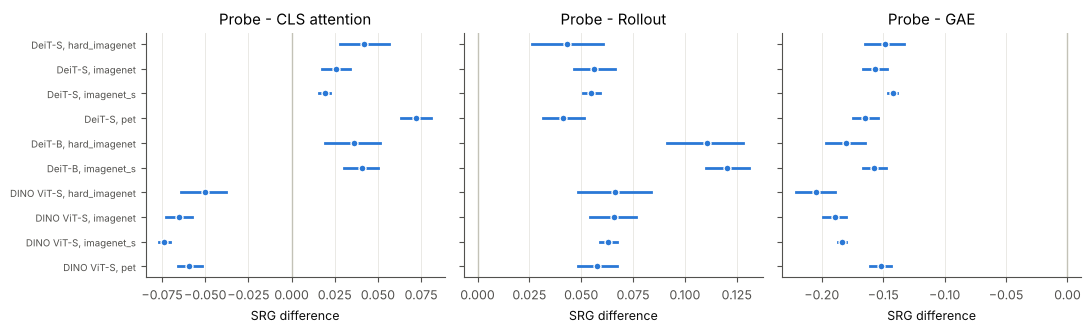

In [18]:
srg_comp = comparisons.query("measure == 'srg_agree' and other in ['cls_attention', 'rollout', 'gae']")
counts = (srg_comp.assign(model=srg_comp.model.map(MODEL_LABELS), other=srg_comp.other.map(label))
          .groupby(['other', 'model']).verdict.value_counts().unstack(fill_value=0))
print('Registered main comparisons: probe minus opponent, paired bootstrap 95% CI, counted over datasets')
display(counts)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
srg_comp = srg_comp.assign(row=srg_comp.model.map(MODEL_LABELS) + ', ' + srg_comp.dataset)
order_rows = list(dict.fromkeys(srg_comp.sort_values(['model', 'dataset']).row))
for ax, other in zip(axes, ['cls_attention', 'rollout', 'gae']):
    part = srg_comp.query('other == @other').set_index('row').loc[order_rows]
    for y, (_, r) in enumerate(part.iterrows()):
        ax.plot([r.low, r.high], [y, y], color=BLUE, lw=2)
        ax.plot(r.difference, y, 'o', color=BLUE, ms=5, mec='white')
    ax.axvline(0, color='#c3c2b7', lw=1)
    ax.set(title=f'Probe - {label(other)}', xlabel='SRG difference')
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(range(len(order_rows)), order_rows, fontsize=7)
axes[0].invert_yaxis()
plt.tight_layout()

ImageNet-S secondary faithfulness measures:


DeiT-S              DINO ViT-S              DeiT-B  \
                       SaCo keep probe K       SaCo keep probe K   SaCo   
method                                                                    
Probe (ours)          0.084        0.958      0.348        0.976 -0.006   
CLS attention        -0.094        0.947      0.300        0.977 -0.204   
Rollout               0.133        0.945      0.165        0.967  0.118   
GAE                   0.481        0.981      0.548        0.986  0.483   
Grad-CAM              0.441        0.968      0.659        0.978  0.306   
Integrated Gradients  0.108        0.902      0.287        0.970  0.098   
Centre (reference)    0.056        0.927      0.094        0.957  0.070   
Random (reference)   -0.003        0.918      0.005        0.945 -0.013   

                                   
                     keep probe K  
method                             
Probe (ours)                0.992  
CLS attention               0.992  
Rollout                     0.984  
GAE                         0.996  
Grad-CAM                    0.989  
Integrated Gradients        0.974  
Centre (reference)          0.983  
Random (reference)          0.977

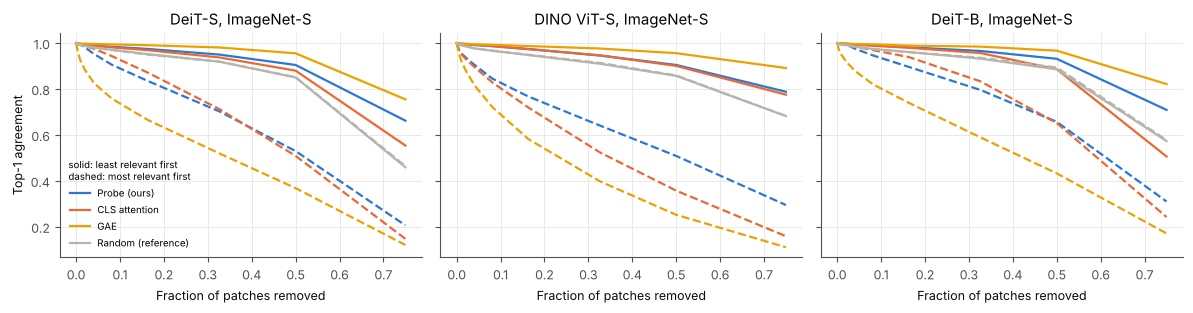

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, model_name in zip(axes, MODELS):
    curves = pd.read_csv(run(f'e4_imagenet_s_{model_name}') / 'analysis_curves.csv')
    for method in ['probe_mass', 'cls_attention', 'gae', 'random']:
        for condition, style in [('drop_bottom', '-'), ('drop_top', '--')]:
            part = curves.query('method == @method and condition == @condition').sort_values('budget')
            ax.plot(np.r_[0, part.budget] / 196, np.r_[1, part.agree], style, color=METHOD_COLORS[method], lw=1.6,
                    label=label(method) if condition == 'drop_bottom' else None)
    ax.set(title=f'{MODEL_LABELS[model_name]}, ImageNet-S', xlabel='Fraction of patches removed')
axes[0].set_ylabel('Top-1 agreement')
axes[0].legend(fontsize=7, title='solid: least relevant first\ndashed: most relevant first', title_fontsize=7)
plt.tight_layout()

extra = {}
for model_name in MODELS:
    folder = run(f'e4_imagenet_s_{model_name}')
    saco = pd.read_csv(folder / 'analysis_saco.csv').set_index('method')['mean']
    fixed = pd.read_csv(folder / 'analysis_faithfulness.csv').query("measure == 'keep_probe_k_agree'").set_index('method')['mean']
    extra[(MODEL_LABELS[model_name], 'SaCo')] = saco
    extra[(MODEL_LABELS[model_name], 'keep probe K')] = fixed
print('ImageNet-S secondary faithfulness measures:')
display(pick(pd.DataFrame(extra), MAIN).rename(index=label))

**解读：**

- 在**不用梯度**的方法里，探针在 DeiT-S（4/4 个数据集）和 DeiT-B（2/2）上最忠实；在 DINO 上低于 CLS 注意力（DINO 的分类头直接读最后 4 层的 CLS）。
- 探针在全部组合中都高于 Rollout。
- **GAE 在全部 10 个组合中都明显更忠实。** 这是最重要的负面结果。一个可能原因是 GAE 针对预测类别，而删图块检验检查的正是这个类别是否保持；这一点没有专门检验。
- 固定预算（K ≈ 135/162 个图块，占全部的 69%/83%）是一个比较宽松的检验，结论与 SRG 相同。

### 5.3 成本

In [20]:
cost = {}
for model_name in MODELS:
    table = pd.read_csv(run(f'e4_imagenet_s_{model_name}') / 'analysis_cost.csv').set_index('method')['ms_per_image']
    cost[(MODEL_LABELS[model_name], 'ms / image')] = table
    cost[(MODEL_LABELS[model_name], 'x forward')] = table / table['forward']
cost = pd.DataFrame(cost).loc[['forward', 'probe_mass', 'cls_attention', 'rollout', 'gradcam', 'gae', 'integrated_gradients']]
print('GPU time per image (A100, median per batch; DeiT-S and DINO batch 128, DeiT-B batch 64):')
display(cost.rename(index=lambda m: 'one forward pass' if m == 'forward' else label(m)).round(2))

GPU time per image (A100, median per batch; DeiT-S and DINO batch 128, DeiT-B batch 64):


DeiT-S           DINO ViT-S               DeiT-B  \
                     ms / image x forward ms / image x forward ms / image   
method                                                                      
one forward pass          0.580     1.000      0.580     1.000      2.010   
Probe (ours)              0.650     1.130      0.650     1.130      2.160   
CLS attention             0.580     1.010      0.610     1.050      2.030   
Rollout                   0.700     1.210      0.700     1.210      2.230   
Grad-CAM                  0.650     1.120      0.650     1.120      2.230   
GAE                       1.490     2.590      1.500     2.600      4.690   
Integrated Gradients     26.660    46.360     26.870    46.510     88.980   

                                
                     x forward  
method                          
one forward pass         1.000  
Probe (ours)             1.070  
CLS attention            1.010  
Rollout                  1.110  
Grad-CAM                 1.110  
GAE                      2.330  
Integrated Gradients    44.200

### 5.4 健全性检验：解释图真的依赖训练好的权重吗？

从输出端往输入端逐级重新随机初始化（分类头 → 第 12 块 → … → 第 1 块 → 嵌入层），看解释图和原图的 Spearman 相关（ImageNet-S，1,000 张）。真正反映模型的解释应该跟着变；全部 12 块随机化后中位数 < 0.5 为通过。

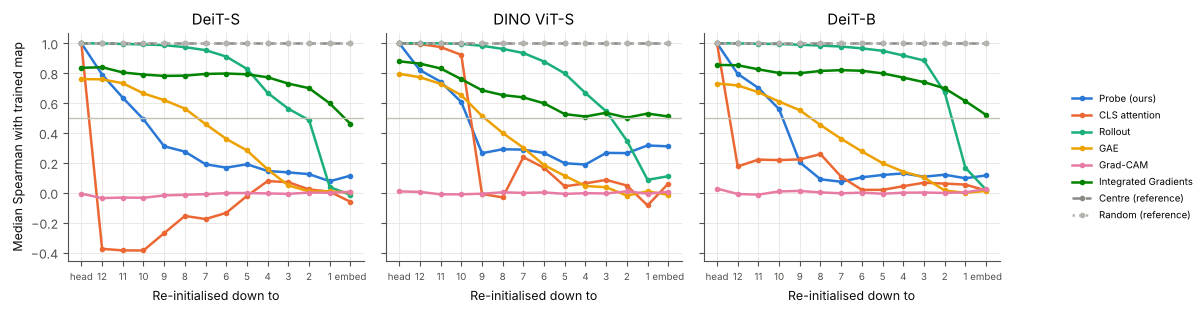

All 12 blocks re-initialised: median Spearman (verdict; references fail by design)


,DeiT-S,DINO ViT-S,DeiT-B
method,,,
Probe (ours),0.08 (pass),0.32 (pass),0.1 (pass)
CLS attention,0.01 (pass),-0.08 (pass),0.05 (pass)
Rollout,0.04 (pass),0.09 (pass),0.17 (pass)
GAE,0.01 (pass),0.01 (pass),-0.0 (pass)
Grad-CAM,-0.0 (pass),-0.01 (pass),0.0 (pass)
Integrated Gradients,0.6 (fail),0.53 (fail),0.61 (fail)
Centre (reference),1.0 (fail),1.0 (fail),1.0 (fail)
Random (reference),1.0 (fail),1.0 (fail),1.0 (fail)


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
verdicts = {}
for ax, model_name in zip(axes, MODELS):
    table = pd.read_csv(run(f'sanity_{model_name}') / 'analysis_sanity.csv')
    steps = table.drop_duplicates('step').sort_values('step')
    for method in MAIN:
        part = table.query('method == @method').sort_values('step')
        ax.plot(part.step, part['median'], METHOD_STYLES.get(method, '-'), color=METHOD_COLORS[method], lw=1.8,
                marker='o', ms=3, label=label(method))
    ax.axhline(.5, color='#c3c2b7', lw=1)
    ax.set_xticks(steps.step, [s.removeprefix('block') for s in steps.level], fontsize=7)
    ax.set(title=MODEL_LABELS[model_name], xlabel='Re-initialised down to')
    result = pd.read_csv(run(f'sanity_{model_name}') / 'analysis_verdicts.csv').set_index('method')
    verdicts[MODEL_LABELS[model_name]] = result['median'].round(2).astype(str) + ' (' + result['verdict'] + ')'
axes[0].set_ylabel('Median Spearman with trained map')
plt.tight_layout(rect=(0, 0, .85, 1))
fig.legend(*axes[0].get_legend_handles_labels(), fontsize=7, loc='center right')
plt.show()
print('All 12 blocks re-initialised: median Spearman (verdict; references fail by design)')
display(pick(pd.DataFrame(verdicts), MAIN).rename(index=label))

**解读：** 探针在三个模型上都通过。IG 在三个模型上都没通过：权重全被打乱后，它的图仍和原来相似，更多反映图片本身。只随机化分类头时，探针、CLS 注意力、Rollout 完全不变（相关 = 1），因为它们与类别无关，这是登记过的性质。DINO 上探针在权重全乱后仍有约 0.3 的相似度，说明有一部分来自图片本身的结构。

### 5.5 RQ3：扣除中心偏差后，还偏向物体吗？（E4 合理性）

In [22]:
enrich, enrich_comp = {}, []
for dataset, model_name, folder in e4_runs():
    path = folder / 'analysis_plausibility.csv'
    if path.exists():
        table = pd.read_csv(path).query("measure == 'enrichment'").set_index('method')
        enrich[(dataset, MODEL_LABELS[model_name])] = table['mean']
        enrich_comp.append(pd.read_csv(folder / 'analysis_comparisons.csv').query("measure == 'enrichment'"))
enrich = pick(pd.DataFrame(enrich), MAIN + ['mask']).rename(index=label)
print('Same-distance-ring enrichment (0 = same as the centre prior; larger = more on the object)')
display(enrich)
enrich_comp = pd.concat(enrich_comp)
display(enrich_comp.assign(model=enrich_comp.model.map(MODEL_LABELS)).groupby(['other', 'model']).verdict
        .value_counts().unstack(fill_value=0))

Same-distance-ring enrichment (0 = same as the centre prior; larger = more on the object)


imagenet_s                   hard_imagenet             \
                            DeiT-S DINO ViT-S DeiT-B        DeiT-S DINO ViT-S   
method                                                                          
Probe (ours)                 0.114      0.158  0.067         0.061      0.094   
CLS attention                0.089      0.238  0.047         0.036      0.144   
Rollout                      0.110      0.144  0.045         0.061      0.061   
GAE                          0.204      0.221  0.196         0.176      0.178   
Grad-CAM                     0.186      0.120  0.170         0.147      0.154   
Integrated Gradients         0.008      0.152  0.004        -0.008      0.116   
Centre (reference)           0.000      0.000  0.000        -0.001     -0.002   
Random (reference)          -0.000     -0.000 -0.000         0.002     -0.001   
Object mask (reference)      0.448      0.444  0.448         0.653      0.651   

                                  pet             
                        DeiT-B DeiT-S DINO ViT-S  
method                                            
Probe (ours)             0.029  0.107      0.151  
CLS attention            0.015  0.083      0.235  
Rollout                  0.017  0.119      0.163  
GAE                      0.162  0.154      0.203  
Grad-CAM                 0.106  0.147      0.083  
Integrated Gradients    -0.007  0.022      0.154  
Centre (reference)      -0.001  0.000      0.000  
Random (reference)       0.001 -0.000     -0.000  
Object mask (reference)  0.653  0.320      0.320

verdict                   higher  lower  uncertain
other         model                               
centre        DINO ViT-S       3      0          0
              DeiT-B           2      0          0
              DeiT-S           3      0          0
cls_attention DINO ViT-S       0      3          0
              DeiT-B           2      0          0
              DeiT-S           3      0          0
gae           DINO ViT-S       0      3          0
              DeiT-B           0      2          0
              DeiT-S           0      3          0
rollout       DINO ViT-S       2      1          0
              DeiT-B           2      0          0
              DeiT-S           1      1          1

**解读：** 探针在全部 8 个"数据集 × 模型"组合中都明显大于 0，所以它偏向物体**不只是因为物体在中间**。这修正了早期 Pet 实验的结论（决策 A14），当时比较的是"名单并集中物体的比例"，而这里比较的是注意力权重落在哪里。GAE 在多数组合中最高。

### 5.6 E5：把物体移到画面一角

同一张图先居中裁剪，再把裁剪窗口往四角各移 48 像素（ImageNet-S 1,515 张），看解释图落在物体上的比例下降多少。下降越少，越说明解释图跟着物体走。

In [23]:
shift = {}
for model_name in MODELS:
    table = pd.read_csv(run(f'e5_shifted_{model_name}') / 'analysis_shift.csv').query("measure == 'mass_drop'")
    shift[MODEL_LABELS[model_name]] = table.set_index('method').apply(ci, axis=1)
print('Drop in object mass share, centre crop -> corner crops (smaller = follows the object)')
display(pick(pd.DataFrame(shift), MAIN).rename(index=label))
e5 = pd.concat([pd.read_csv(run(f'e5_shifted_{m}') / 'analysis_comparisons.csv') for m in MODELS])
display(e5.query("measure == 'mass_drop' and other == 'centre'")[['model', 'base', 'other', 'difference', 'low', 'high', 'verdict']])

Drop in object mass share, centre crop -> corner crops (smaller = follows the object)


,DeiT-S,DINO ViT-S,DeiT-B
method,,,
Probe (ours),"0.035 [0.030, 0.040]","0.003 [-0.000, 0.006]","0.045 [0.039, 0.052]"
CLS attention,"0.039 [0.033, 0.044]","0.006 [0.003, 0.008]","0.046 [0.039, 0.052]"
Rollout,"0.030 [0.027, 0.034]","0.030 [0.027, 0.034]","0.034 [0.031, 0.038]"
GAE,"0.014 [0.011, 0.017]","0.011 [0.008, 0.013]","0.015 [0.012, 0.018]"
Centre (reference),"0.056 [0.050, 0.061]","0.056 [0.050, 0.061]","0.056 [0.050, 0.061]"


,model,base,other,difference,low,high,verdict
0,deit,probe_mass,centre,-0.021,-0.027,-0.015,lower
0,dino,probe_mass,centre,-0.053,-0.058,-0.047,lower
0,deit_b,probe_mass,centre,-0.010,-0.017,-0.004,lower


### 5.7 E6：模型真的依赖物体本身吗？（中心配对删除）

从读取名单中删去物体 token，对比删去同样数量、离中心距离相同的非物体 token。**剩余比例** = 排除中心位置后，物体效应还剩多少。

In [24]:
e6 = []
for dataset in ['imagenet_s', 'hard_imagenet']:
    table = pd.read_csv(run(f'e6_deletion_{dataset}') / 'summary.csv').query("category == 'foreground'")
    e6.append(table.assign(dataset=dataset))
e6 = pd.concat(e6)
e6_table = pd.DataFrame({
    'dataset': e6.dataset, 'model': e6.model.map(MODEL_LABELS), 'images': e6.n,
    'agree: object removed': e6.target, 'agree: same-distance removed': e6.centre_matched,
    'difference [95% CI]': e6.apply(lambda r: f'{r.target_minus_matched:+.3f} [{r.target_minus_matched_low:+.3f}, '
                                              f'{r.target_minus_matched_high:+.3f}]', axis=1),
    'remaining share': e6.remaining})
display(e6_table.set_index(['dataset', 'model']))

images  agree: object removed  \
dataset       model                                        
imagenet_s    DeiT-S        11740                  0.490   
              DINO ViT-S    11642                  0.361   
              MiTA-DeiT-S   11642                  0.652   
hard_imagenet DeiT-S          737                  0.657   
              DINO ViT-S      736                  0.515   
              MiTA-DeiT-S     736                  0.811   

                           agree: same-distance removed  \
dataset       model                                       
imagenet_s    DeiT-S                              0.731   
              DINO ViT-S                          0.550   
              MiTA-DeiT-S                         0.879   
hard_imagenet DeiT-S                              0.723   
              DINO ViT-S                          0.575   
              MiTA-DeiT-S                         0.904   

                               difference [95% CI]  remaining share  
dataset       model                                                  
imagenet_s    DeiT-S       -0.241 [-0.249, -0.232]            0.787  
              DINO ViT-S   -0.189 [-0.196, -0.181]            0.783  
              MiTA-DeiT-S  -0.227 [-0.234, -0.219]            0.836  
hard_imagenet DeiT-S       -0.066 [-0.088, -0.045]            0.682  
              DINO ViT-S   -0.060 [-0.083, -0.037]            0.625  
              MiTA-DeiT-S  -0.093 [-0.114, -0.070]            0.701

**解读：** 在所有组合中，删物体比删同距离的其他 token 伤害更大，排除中心位置后物体效应还剩 63%–84%。模型确实依赖物体本身。

### 5.8 E7：和人的判断比较（ClickMe，每个模型 17,408 张）

人类图本身偏向中间：中心高斯与人类图的相关就有约 0.41。所以主指标用**图片特异部分** = 与本图人类图的相关 − 与另一张图人类图的相关，中心参照为 0。

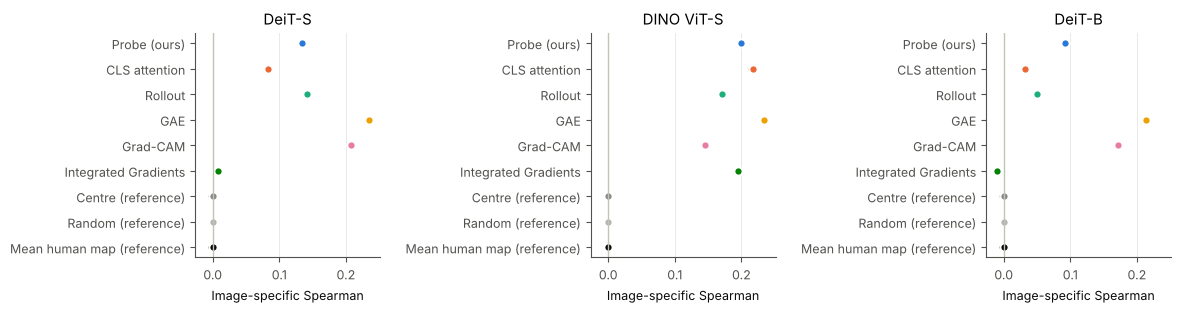

Image-specific Spearman (own human map - another image's map), pixel level:


,DeiT-S,DINO ViT-S,DeiT-B
method,,,
Probe (ours),"0.135 [0.132, 0.137]","0.199 [0.195, 0.203]","0.092 [0.090, 0.095]"
CLS attention,"0.083 [0.080, 0.086]","0.217 [0.212, 0.221]","0.032 [0.029, 0.034]"
Rollout,"0.141 [0.137, 0.145]","0.171 [0.166, 0.176]","0.050 [0.046, 0.054]"
GAE,"0.234 [0.230, 0.238]","0.234 [0.230, 0.239]","0.213 [0.209, 0.218]"
Grad-CAM,"0.208 [0.204, 0.213]","0.145 [0.141, 0.150]","0.172 [0.168, 0.176]"
Integrated Gradients,"0.008 [0.004, 0.011]","0.195 [0.191, 0.200]","-0.010 [-0.014, -0.006]"
Centre (reference),"-0.000 [-0.005, 0.005]","-0.000 [-0.005, 0.005]","0.000 [-0.005, 0.005]"
Random (reference),"0.000 [-0.002, 0.002]","0.000 [-0.002, 0.002]","0.000 [-0.001, 0.002]"
Mean human map (reference),"-0.000 [-0.005, 0.005]","-0.000 [-0.005, 0.005]","-0.000 [-0.005, 0.005]"


Raw Spearman with the own human map (centre-biased):


,DeiT-S,DINO ViT-S,DeiT-B
method,,,
Probe (ours),0.205,0.364,0.129
CLS attention,0.135,0.449,0.069
Rollout,0.140,0.239,-0.056
GAE,0.359,0.425,0.346
Grad-CAM,0.351,0.213,0.306
Integrated Gradients,-0.048,0.333,-0.073
Centre (reference),0.414,0.414,0.414
Random (reference),-0.000,-0.000,0.000
Mean human map (reference),0.419,0.419,0.419


In [25]:
human, human_raw = {}, {}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharex=True)
for ax, model_name in zip(axes, MODELS):
    table = pd.read_csv(run(f'e7_clickme_{model_name}') / 'analysis_alignment.csv')
    specific = table.query("measure == 'specific_pixel'").set_index('method')
    human[MODEL_LABELS[model_name]] = specific.apply(ci, axis=1)
    human_raw[MODEL_LABELS[model_name]] = table.query("measure == 'spearman_pixel'").set_index('method')['mean']
    interval_dots(ax, specific, MAIN + ['mean_human'])
    ax.axvline(0, color='#c3c2b7', lw=1)
    ax.set(title=MODEL_LABELS[model_name], xlabel='Image-specific Spearman')
plt.tight_layout()
plt.show()
order_ = MAIN + ['mean_human']
print('Image-specific Spearman (own human map - another image\'s map), pixel level:')
display(pick(pd.DataFrame(human), order_).rename(index=label))
print('Raw Spearman with the own human map (centre-biased):')
display(pick(pd.DataFrame(human_raw), order_).rename(index=label))

**解读：** 探针的图片特异部分在三个模型上都明显大于 0；在不用梯度的方法里总体最好或接近最好；低于 GAE 和 Grad-CAM。原始相关上，中心高斯和平均人类图高于登记的 4 个探针变体（符合预测）；但 DINO 第 11 层的单层探针图（0.417）略高于中心高斯（0.414），仍低于平均人类图（0.419）。逐层结果见第 6 部分。

### 5.9 E8：部件层面（PartImageNet）

> 这些图片来自 ImageNet **训练集**，模型训练时见过；DeiT-B 只用了 val + test 两部分（决策 B19）。结论要打一些折扣。

**(a) 解释图是否偏爱头？** 头部富集 = 解释图分给头的比例 ÷ 头占物体面积的比例（6 类动物，按图片数加权合并）。

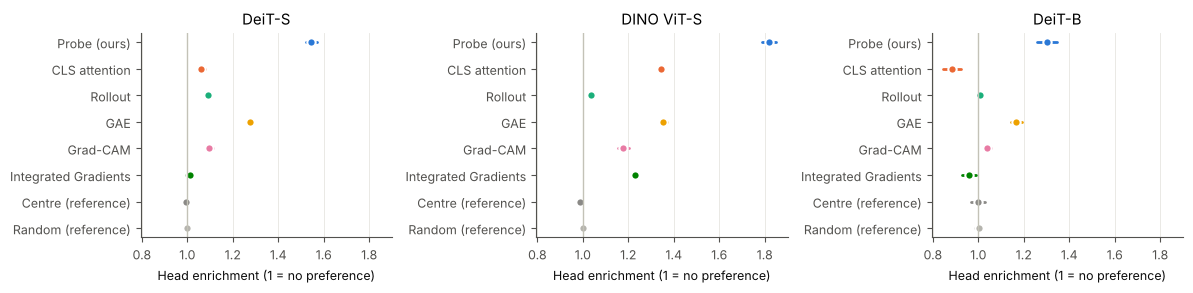

,DeiT-S,DINO ViT-S,DeiT-B
method,,,
Probe (ours),1.545,1.818,1.301
CLS attention,1.062,1.344,0.883
Rollout,1.092,1.035,1.008
GAE,1.276,1.354,1.167
Grad-CAM,1.096,1.177,1.040
Integrated Gradients,1.010,1.228,0.959
Centre (reference),0.995,0.988,0.998
Random (reference),1.001,1.001,1.001


DeiT-S probe head enrichment by animal group:


supercategory,Quadruped,Biped,Fish,Bird,Snake,Reptile
n,7091.000,2489.000,1345.000,2323.000,2513.000,3454.000
mean,1.638,1.789,1.075,1.992,1.230,1.288


In [26]:
def pooled_head_enrichment(model_name):
    table = pd.read_csv(run(f'e8_parts_{model_name}') / 'analysis_parts.csv').query("measure == 'enrichment'")
    heads = table[table.supercategory.isin(ANIMALS) & (table.name == 'Head')]
    return heads.assign(w=heads.n).groupby('method').apply(
        lambda g: pd.Series({c: (g[c] * g.w).sum() / g.w.sum() for c in ('mean', 'low', 'high')}), include_groups=False)


heads = {m: pooled_head_enrichment(m) for m in MODELS}
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharex=True)
for ax, model_name in zip(axes, MODELS):
    interval_dots(ax, heads[model_name], MAIN)
    ax.axvline(1, color='#c3c2b7', lw=1)
    ax.set(title=MODEL_LABELS[model_name], xlabel='Head enrichment (1 = no preference)')
plt.tight_layout()
plt.show()
display(pick(pd.DataFrame({MODEL_LABELS[m]: heads[m]['mean'] for m in MODELS}), MAIN).rename(index=label))
by_animal = (pd.read_csv(run('e8_parts_deit') / 'analysis_parts.csv')
             .query("measure == 'enrichment' and name == 'Head' and method == 'probe_mass'")
             .set_index('supercategory').loc[ANIMALS, ['n', 'mean']])
print('DeiT-S probe head enrichment by animal group:')
display(by_animal.T)

**(b) 模型自己是否依赖头？** 从一个部件随机删 4 个图块（所有层都不读），看原 top-1 的对数概率下降多少。对照：随机删 4 个物体图块、4 个纯背景图块。

In [27]:
reliance = []
for model_name in MODELS:
    table = pd.read_csv(run(f'e8_parts_{model_name}') / 'analysis_reliance.csv').query('removed == 4')
    reliance.append(table.assign(model=MODEL_LABELS[model_name]))
reliance = pd.concat(reliance)
parts = reliance[reliance.supercategory.isin(['Quadruped', 'Biped', 'Bird']) | (reliance.supercategory == 'control')]
display(parts.pivot_table(index=['supercategory', 'name'], columns='model', values='mean')[[MODEL_LABELS[m] for m in MODELS]])
e8 = pd.concat([pd.read_csv(run(f'e8_parts_{m}') / 'analysis_comparisons.csv') for m in MODELS])
print('Same image, head removed minus body removed (log-probability drop, 4 patches):')
display(e8.query("measure == 'reliance_log_drop_r4'")[['model', 'n', 'difference', 'low', 'high', 'verdict']])

model                     DeiT-S  DINO ViT-S  DeiT-B
supercategory name                                  
Biped         Body         0.012       0.012   0.003
              Foot         0.006       0.009   0.007
              Hand         0.007       0.009   0.002
              Head         0.037       0.033   0.014
              Tail         0.003       0.008   0.001
Bird          Body         0.010       0.013   0.007
              Foot         0.009      -0.001   0.008
              Head         0.012       0.025   0.006
              Tail         0.005       0.007   0.000
              Wing         0.021       0.014   0.004
Quadruped     Body         0.015       0.011   0.005
              Foot         0.008       0.009   0.003
              Head         0.033       0.037   0.009
              Tail         0.007       0.009   0.001
control       background   0.001      -0.000   0.001
              object       0.021       0.021   0.012

Same image, head removed minus body removed (log-probability drop, 4 patches):


,model,n,difference,low,high,verdict
5,deit,14693,0.017,0.014,0.020,higher
5,dino,14815,0.021,0.019,0.024,higher
5,deit_b,2234,0.007,0.004,0.011,higher


**(c) 解释图最偏爱的部件，是不是模型最依赖的部件？**（每张至少有 2 个可删部件的图）

In [28]:
agreement = {}
for model_name in MODELS:
    table = pd.read_csv(run(f'e8_parts_{model_name}') / 'analysis_agreement.csv').set_index('method')
    agreement[MODEL_LABELS[model_name]] = table.apply(lambda r: ci(r, 1, 100), axis=1)
display(pick(pd.DataFrame(agreement), MAIN + ['chance']).rename(index=label))
display(e8.query("measure == 'head_enrichment' or measure == 'agreement'")
        [['measure', 'model', 'base', 'other', 'difference', 'low', 'high', 'verdict']])

,DeiT-S,DINO ViT-S,DeiT-B
method,,,
Probe (ours),"46.6 [45.9, 47.3]","52.2 [51.5, 52.9]","44.4 [42.5, 46.1]"
CLS attention,"41.1 [40.4, 41.8]","52.2 [51.5, 52.9]","38.1 [36.3, 39.9]"
Rollout,"45.9 [45.2, 46.6]","45.1 [44.5, 45.8]","42.8 [40.9, 44.7]"
GAE,"51.4 [50.7, 52.1]","56.4 [55.6, 57.1]","50.3 [48.3, 52.2]"
Grad-CAM,"45.8 [45.1, 46.6]","49.2 [48.5, 49.9]","45.5 [43.6, 47.3]"
Integrated Gradients,"42.4 [41.7, 43.1]","50.1 [49.4, 50.8]","40.4 [38.5, 42.2]"
Centre (reference),"40.1 [39.4, 40.7]","40.2 [39.4, 40.9]","39.3 [37.5, 41.2]"
Random (reference),"40.7 [40.0, 41.4]","40.3 [39.6, 40.9]","40.3 [38.6, 42.1]"
chance,"39.9 [39.7, 40.0]","39.8 [39.6, 39.9]","39.8 [39.4, 40.1]"


,measure,model,base,other,difference,low,high,verdict
0,head_enrichment,deit,probe_mass,centre,0.550,0.536,0.562,higher
1,head_enrichment,deit,probe_mass,random,0.544,0.532,0.555,higher
2,head_enrichment,deit,probe_mass,cls_attention,0.483,0.474,0.491,higher
3,head_enrichment,deit,probe_mass,rollout,0.453,0.442,0.463,higher
4,head_enrichment,deit,probe_mass,gae,0.268,0.260,0.276,higher
6,agreement,deit,probe_mass,centre,0.066,0.056,0.075,higher
7,agreement,deit,probe_mass,random,0.060,0.049,0.070,higher
8,agreement,deit,gae,centre,0.114,0.104,0.122,higher
9,agreement,deit,gae,random,0.107,0.097,0.117,higher
10,agreement,deit,cls_attention,centre,0.010,0.001,0.019,higher


**解读：**

- 探针的头部富集在三个模型上都是**所有方法中最高**，也高于 GAE。
- 模型自己确实更依赖头：对四足和两足动物，删头的伤害大约是删身体的 2–3 倍（鸟、蛇、爬行动物、鱼有例外）。
- 但在"逐张图对得上"上，探针（约 44%–52%）高于瞎猜（约 40%），低于 GAE。所以探针可能带有一种"总是偏爱头"的通用倾向，而不完全是逐张图判断。

### 5.10 E3 前提：深层 token 还代表原位置吗？

每层训练一个线性分类器，从 token 猜它原来的位置（196 选 1，瞎猜 0.5%）。

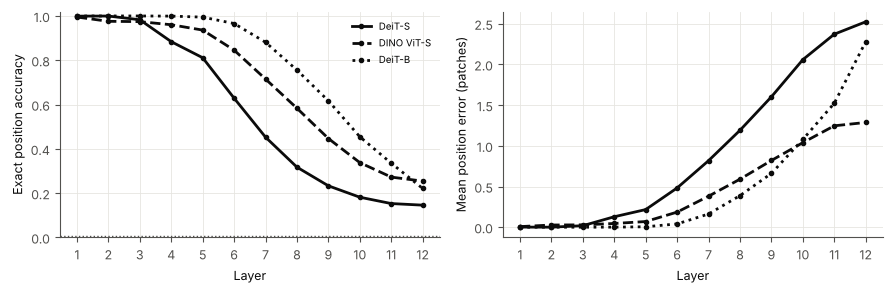

layer,1,3,5,7,9,11,12
model,,,,,,,
DeiT-S,99.9%,98.3%,81.1%,45.3%,23.3%,15.3%,14.6%
DINO ViT-S,99.5%,97.4%,93.6%,71.5%,44.7%,27.3%,25.4%
DeiT-B,100.0%,100.0%,99.5%,88.1%,61.7%,33.5%,22.1%


In [29]:
identity = pd.concat([pd.read_csv(run(f'e3_identity_{m}') / 'identity.csv') for m in MODELS])
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for (model_name, part), style in zip(identity.groupby('model', sort=False), ['-', '--', ':']):
    part = part.sort_values('layer')
    axes[0].plot(part.layer, part.position_accuracy, style, color=INK, lw=2, marker='o', ms=3, label=MODEL_LABELS[model_name])
    axes[1].plot(part.layer, part.error_distance, style, color=INK, lw=2, marker='o', ms=3, label=MODEL_LABELS[model_name])
axes[0].axhline(1 / 196, color=QUIET, ls=':', lw=1)
axes[0].set(xlabel='Layer', ylabel='Exact position accuracy', xticks=range(1, 13), ylim=(0, 1.02))
axes[1].set(xlabel='Layer', ylabel='Mean position error (patches)', xticks=range(1, 13))
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()
display(identity.pivot(index='model', columns='layer', values='position_accuracy').loc[MODELS, [1, 3, 5, 7, 9, 11, 12]]
        .rename(index=MODEL_LABELS).map(lambda v: f'{v:.1%}'))

**解读：** 浅中层的 token 基本就是原来的图块；深层 token 只大致代表原位置（DeiT-S 第 12 层平均偏差约 2.5 个图块）。所以深层探针图应理解为"这附近的区域"。

## 6 逐层综合

三组独立的测量放在一起：和人的一致（E7）、对动物头部的偏爱（E8）、token 是否仍代表原位置（E3）。

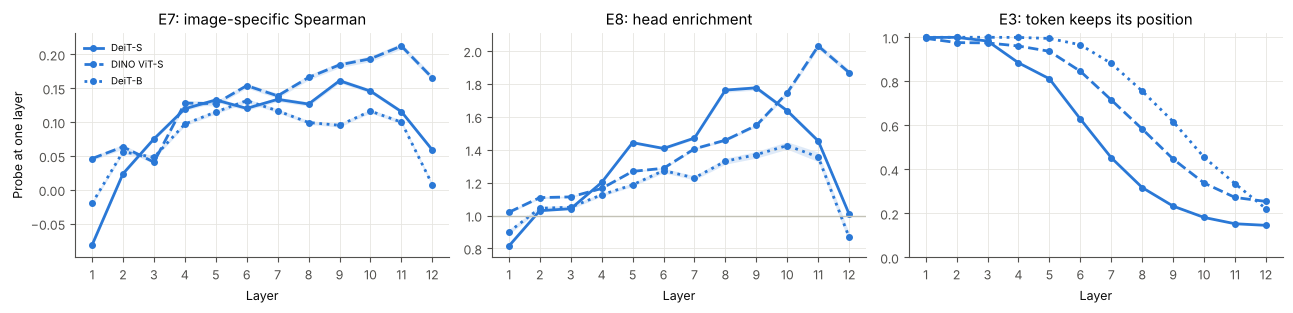

,DeiT-S,DINO ViT-S,DeiT-B
ClickMe peak layer,9,11,6
ClickMe peak / layer 12,0.161 / 0.059,0.212 / 0.165,0.132 / 0.008
head-enrichment peak layer,9,11,10
head enrichment peak / layer 12,1.78 / 1.01,2.03 / 1.87,1.43 / 0.87
position accuracy layer 12,14.6%,25.4%,22.1%


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
peaks = {}
for model_name, style in zip(MODELS, ['-', '--', ':']):
    human_layers = (pd.read_csv(run(f'e7_clickme_{model_name}') / 'analysis_layers.csv')
                    .query("measure == 'specific_pixel'").sort_values('layer'))
    head_layers = pd.read_csv(run(f'e8_parts_{model_name}') / 'analysis_layers.csv').sort_values('layer')
    position = identity.query('model == @model_name').sort_values('layer')
    band(axes[0], human_layers.layer, human_layers, BLUE, label=MODEL_LABELS[model_name], style=style)
    band(axes[1], head_layers.layer, head_layers, BLUE, label=MODEL_LABELS[model_name], style=style)
    axes[2].plot(position.layer, position.position_accuracy, style, color=BLUE, lw=2, marker='o', ms=4,
                 label=MODEL_LABELS[model_name])
    peaks[MODEL_LABELS[model_name]] = {
        'ClickMe peak layer': int(human_layers.loc[human_layers['mean'].idxmax(), 'layer']),
        'ClickMe peak / layer 12': f"{human_layers['mean'].max():.3f} / {human_layers['mean'].iloc[-1]:.3f}",
        'head-enrichment peak layer': int(head_layers.loc[head_layers['mean'].idxmax(), 'layer']),
        'head enrichment peak / layer 12': f"{head_layers['mean'].max():.2f} / {head_layers['mean'].iloc[-1]:.2f}",
        'position accuracy layer 12': f"{position.position_accuracy.iloc[-1]:.1%}"}
axes[0].set(title='E7: image-specific Spearman', ylabel='Probe at one layer')
axes[1].set(title='E8: head enrichment')
axes[1].axhline(1, color='#c3c2b7', lw=1)
axes[2].set(title='E3: token keeps its position', ylim=(0, 1.02))
for ax in axes:
    ax.set(xlabel='Layer', xticks=range(1, 13))
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()
display(pd.DataFrame(peaks))

**解读：** 最"像人"、最偏爱头的读取出现在中后层（DeiT-S 第 8–9 层，DINO 第 11 层）。有监督的 DeiT-S、DeiT-B 在最后一层离开物体，同时 token 也不再精确代表原位置；自监督的 DINO 保持得更好。

> **注意：** 我们只对探针做了逐层分析，没有和"逐层的普通注意力（不加 top-k）"比较。所以只能说"探针逐层图给出了一致的层级规律"，不能说"只有探针能看到这一规律"（见第 8 部分）。

## 7 预测对账（由代码从结果表判定）

每条预测都在正式运行前登记（`docs/decisions.md` B11–B15）。下面的判定由代码直接从结果表计算，判定口径与登记时相同："高于/低于"看配对 bootstrap 区间是否不含 0；"相当"指区间含 0 或差的绝对值 < 0.05；"接近 0"指区间含 0 或绝对值 < 0.02。

In [31]:
ledger = []


def record(experiment, prediction, results, evidence):
    """results: list of booleans, one per model/dataset combination."""
    verdict = 'holds' if all(results) else 'does not hold' if not any(results) else 'partly holds'
    ledger.append(dict(experiment=experiment, prediction=prediction, verdict=verdict, evidence=evidence))


S = lambda m: MODEL_LABELS[m]

# E3
pos = identity.pivot(index='model', columns='layer', values='position_accuracy')
record('E3', 'Position accuracy falls with depth, stays far above chance at layer 12; DINO falls less than DeiT-S',
       [all(pos.loc[m, 12] < pos.loc[m, 1] and pos.loc[m, 12] > 10 / 196 for m in MODELS),
        pos.loc['dino', 12] > pos.loc['deit', 12]],
       ', '.join(f'{S(m)} L12 {pos.loc[m, 12]:.1%}' for m in MODELS))

# E4 faithfulness
srg_c = comparisons.query("measure == 'srg_agree'")
for other in ['cls_attention', 'rollout']:
    part = srg_c.query('other == @other')
    record('E4', f'Probe SRG higher than {label(other)}', list(part.verdict == 'higher'),
           '; '.join(f'{S(m)} {(g.verdict == "higher").sum()}/{len(g)} higher' for m, g in part.groupby('model', sort=False)))
gae = srg_c.query("other == 'gae'")
record('E4', 'Probe SRG comparable to GAE', list((gae.low <= 0) & (gae.high >= 0) | (gae.difference.abs() < .05)),
       f'GAE higher in {(gae.verdict == "lower").sum()}/{len(gae)}; probe - GAE from {gae.difference.min():+.2f} '
       f'to {gae.difference.max():+.2f}')
above, failures = [], []
for dataset, model_name, folder in e4_runs():
    faith = pd.read_csv(folder / 'analysis_faithfulness.csv').query("measure == 'srg_agree'").set_index('method')
    for method in ['probe_mass', 'cls_attention', 'rollout', 'gae', 'gradcam', 'integrated_gradients']:
        ok = faith.loc[method, 'low'] > faith.loc['random', 'high']
        above.append(ok)
        if not ok:
            failures.append(f'{label(method)} on {S(model_name)}/{dataset} ({faith.loc[method, "mean"]:.3f})')
record('E4', 'Every method has SRG above the random map', above,
       'not above random: ' + '; '.join(failures) if failures else 'all above')

# E4 plausibility
plaus_s = {m: pd.read_csv(run(f'e4_imagenet_s_{m}') / 'analysis_plausibility.csv')
           .query("measure == 'enrichment'").set_index('method').loc['probe_mass'] for m in MODELS}
near0 = lambda r: (r['low'] <= 0 <= r['high']) or abs(r['mean']) < .02
record('E4', 'DeiT-S and DeiT-B probe enrichment near 0 after centre control (ImageNet-S)',
       [near0(plaus_s['deit']), near0(plaus_s['deit_b'])],
       f"DeiT-S {ci(plaus_s['deit'])}, DeiT-B {ci(plaus_s['deit_b'])} (both clearly > 0)")
record('E4', 'DINO probe enrichment > 0 after centre control (ImageNet-S)', [plaus_s['dino']['low'] > 0],
       f"DINO {ci(plaus_s['dino'])}")

# E5, E6
e5c = e5.query("measure == 'mass_drop' and other == 'centre'")
record('E5', 'Probe object-mass drop smaller than the centre reference when the object moves', list(e5c.verdict == 'lower'),
       '; '.join(f'{S(r.model)} {r.difference:+.3f} [{r.low:+.3f}, {r.high:+.3f}]' for r in e5c.itertuples()))
record('E6', 'More than half of the object effect remains after centre matching', list(e6.remaining > .5),
       ', '.join(f'{S(r.model)}/{r.dataset} {r.remaining:.0%}' for r in e6.itertuples()))

# E7
raw_ok, spec_ok, spec_fail, best_probe, best_layer = [], [], [], [], []
for model_name in MODELS:
    table = pd.read_csv(run(f'e7_clickme_{model_name}') / 'analysis_alignment.csv')
    raw = table.query("measure == 'spearman_pixel'").set_index('method')['mean']
    probes = raw[['probe_mass', 'probe_count', 'probe_value', 'probe_mass_all']]  # the registered E4 variants
    raw_ok.append(min(raw['centre'], raw['mean_human']) > probes.max())
    best_probe.append(probes.max())
    layer_maps = raw[[m for m in raw.index if m.startswith('probe_layer')]]
    best_layer.append(f"{S(model_name)} {layer_maps.idxmax().removeprefix('probe_')} {layer_maps.max():.3f}")
    specific = table.query("measure == 'specific_pixel'").set_index('method')
    for method in ['probe_mass', 'probe_count', 'probe_value', 'probe_mass_all', 'cls_attention', 'rollout', 'gae',
                   'gradcam', 'integrated_gradients']:
        spec_ok.append(specific.loc[method, 'low'] > 0)
        if not spec_ok[-1]:
            spec_fail.append(f'{label(method)} on {S(model_name)} ({ci(specific.loc[method])})')
record('E7', 'Centre and mean human map have higher raw Spearman than every probe variant (mass/count/value/all layers)',
       raw_ok, f"centre {raw['centre']:.3f}, mean human map {raw['mean_human']:.3f}; best variant: "
       + ', '.join(f'{S(m)} {v:.3f}' for m, v in zip(MODELS, best_probe))
       + '. Not registered, for the record: best single-layer map ' + ', '.join(best_layer))
record('E7', 'Every non-reference method has image-specific Spearman > 0', spec_ok,
       'not > 0: ' + '; '.join(spec_fail) if spec_fail else 'all > 0')
probe_spec = {m: pd.read_csv(run(f'e7_clickme_{m}') / 'analysis_alignment.csv')
              .query("measure == 'specific_pixel' and method == 'probe_mass'")['mean'].item() for m in MODELS}
record('E7', 'DINO probe more human-like (image-specific) than DeiT-S probe', [probe_spec['dino'] > probe_spec['deit']],
       f"DINO {probe_spec['dino']:.3f} vs DeiT-S {probe_spec['deit']:.3f}")

# E8
rel = e8.query("measure == 'reliance_log_drop_r4'")
record('E8', 'Models rely more on the head than on the body (4 patches removed)', list(rel.verdict == 'higher'),
       '; '.join(f'{S(r.model)} {r.difference:+.3f} [{r.low:+.3f}, {r.high:+.3f}]' for r in rel.itertuples()))
record('E8', 'Centre reference head enrichment < 1', [heads[m].loc['centre', 'high'] < 1 for m in MODELS],
       ', '.join(f"{S(m)} {heads[m].loc['centre', 'mean']:.2f}" for m in MODELS))
he = e8.query("measure == 'head_enrichment' and other == 'centre'")
record('E8', 'Probe head enrichment higher than the centre reference', list(he.verdict == 'higher'),
       ', '.join(f"{S(m)} probe {heads[m].loc['probe_mass', 'mean']:.2f}" for m in MODELS))
ag = e8.query("measure == 'agreement' and other == 'random' and base in ['probe_mass', 'gae']")
record('E8', 'Probe and GAE pick the most-relied-on part more often than random', list(ag.verdict == 'higher'),
       '; '.join(f'{S(r.model)} {label(r.base)} {r.difference:+.3f}' for r in ag.itertuples()))

# Sanity and cost
sanity_ok, sanity_fail, head_ok = [], [], []
for model_name in MODELS:
    result = pd.read_csv(run(f'sanity_{model_name}') / 'analysis_verdicts.csv').set_index('method')
    for method in result.index.difference(list(REFERENCES)):
        sanity_ok.append(result.loc[method, 'verdict'] == 'pass')
        if not sanity_ok[-1]:
            sanity_fail.append(f'{label(method)} on {S(model_name)} ({result.loc[method, "median"]:.2f})')
    table = pd.read_csv(run(f'sanity_{model_name}') / 'analysis_sanity.csv').query("level == 'head'").set_index('method')
    head_ok += [table.loc[m, 'median'] > .999 for m in ['probe_mass', 'cls_attention', 'rollout']]
record('Sanity', 'Every non-reference method passes (median Spearman < 0.5)', sanity_ok, 'fails: ' + '; '.join(sanity_fail))
record('Sanity', 'Class-agnostic maps unchanged when only the head is re-initialised', head_ok,
       'probe, CLS attention, Rollout: Spearman 1.0 on all models' if all(head_ok) else 'see 5.4')
cost_ok, cost_text = [], []
for model_name in MODELS:
    c = pd.read_csv(run(f'e4_imagenet_s_{model_name}') / 'analysis_cost.csv').set_index('method')['ms_per_image']
    cost_ok.append(c['probe_mass'] < 2 * max(c['cls_attention'], c['rollout']) and c['probe_mass'] < c['gae']
                   and c['integrated_gradients'] > 10 * c['probe_mass'])
    cost_text.append(f"{S(model_name)} probe {c['probe_mass']:.2f} / GAE {c['gae']:.2f} / IG {c['integrated_gradients']:.1f} ms")
record('Cost', 'Probe in the same order as CLS attention/Rollout, below GAE, >10x below IG', cost_ok, '; '.join(cost_text))

ledger = pd.DataFrame(ledger)
display(ledger)
print(ledger.verdict.value_counts().to_string())

,experiment,prediction,verdict,evidence
0,E3,"Position accuracy falls with depth, stays far above chance at layer 12; DINO falls less than DeiT-S",holds,"DeiT-S L12 14.6%, DINO ViT-S L12 25.4%, DeiT-B L12 22.1%"
1,E4,Probe SRG higher than CLS attention,partly holds,DeiT-S 4/4 higher; DINO ViT-S 0/4 higher; DeiT-B 2/2 higher
2,E4,Probe SRG higher than Rollout,holds,DeiT-S 4/4 higher; DINO ViT-S 4/4 higher; DeiT-B 2/2 higher
3,E4,Probe SRG comparable to GAE,does not hold,GAE higher in 10/10; probe - GAE from -0.21 to -0.14
4,E4,Every method has SRG above the random map,partly holds,not above random: Integrated Gradients on DeiT-B/imagenet_s (-0.001); Integrated Gradients on DeiT-B/hard_imagenet (...
5,E4,DeiT-S and DeiT-B probe enrichment near 0 after centre control (ImageNet-S),does not hold,"DeiT-S 0.114 [0.112, 0.116], DeiT-B 0.067 [0.066, 0.069] (both clearly > 0)"
6,E4,DINO probe enrichment > 0 after centre control (ImageNet-S),holds,"DINO 0.158 [0.155, 0.161]"
7,E5,Probe object-mass drop smaller than the centre reference when the object moves,holds,"DeiT-S -0.021 [-0.027, -0.015]; DINO ViT-S -0.053 [-0.058, -0.047]; DeiT-B -0.010 [-0.017, -0.004]"
8,E6,More than half of the object effect remains after centre matching,holds,"DeiT-S/imagenet_s 79%, DINO ViT-S/imagenet_s 78%, MiTA-DeiT-S/imagenet_s 84%, DeiT-S/hard_imagenet 68%, DINO ViT-S/h..."
9,E7,Centre and mean human map have higher raw Spearman than every probe variant (mass/count/value/all layers),holds,"centre 0.414, mean human map 0.419; best variant: DeiT-S 0.254, DINO ViT-S 0.367, DeiT-B 0.199. Not registered, for ..."


verdict
holds            12
partly holds      4
does not hold     3


**怎么读这张表：** 大部分预测成立。对探针不利的落空主要有两条：探针的忠实性**不**与 GAE 相当（GAE 全部更高），以及 DINO 上探针低于 CLS 注意力。有一条落空方向**比预期好**：DeiT-S、DeiT-B 扣除中心后不是接近 0，而是明显大于 0。另外几条"部分成立"来自对照方法（IG 未通过健全性检验、在 DeiT-B 上与随机图相同）。

## 8 局限与下一步

**已知局限：**

1. **删图块的忠实性落后于梯度方法（GAE、Grad-CAM）。** 这是最重要的负面结果。"GAE 针对类别所以占优"只是推测，没有检验。
2. **缺一个关键对照：不加 top-k 的"完整注意力加总"。** 如果它的图和探针几乎一样，那么 MiTA 的 top-k 读取只贡献了"可执行"这一性质，没有让解释图本身更好。这直接关系到新意。
3. **逐层结论没有和普通注意力的逐层图比较**，所以不能说"只有探针能看到"。
4. **PartImageNet 图片来自训练集**；DeiT-B 只用了 val + test。
5. **深层 token 只大致代表原位置**（E3），深层图的精度约 1–3 个图块。
6. **DINO 上的健全性残余**（全部权重随机化后仍有约 0.3 的相似度）。
7. **类别无关**：探针不能回答"为什么是这个类别而不是那个"。
8. 每项只运行一次（同一 GPU、float32）；区间只反映图片抽样的不确定性。

**建议的下一步（需先登记，再运行）：** 补"完整注意力加总"及其逐层版本，用 E4、E7、E8 同一套检验比较。

## 9 复现命令与核心代码索引

```bash
# one formal run (refuses to run with uncommitted source changes; records the git commit)
python scripts/run.py explanations --config configs/explanations.yaml --model deit --output experiments/<date>_e4_imagenet_s_deit
python scripts/run.py human_alignment --config configs/human_alignment.yaml --model dino --output experiments/<date>_e7_clickme_dino
python scripts/run.py parts --config configs/parts.yaml --model deit --output experiments/<date>_e8_parts_deit
# all v3 analyses and figures from the result files (CPU)
bash scripts/analyze_v3.sh experiments/2026-10-29_v3_
# tests (unit + end-to-end on fake data and random weights)
python -m pytest
```

GPU 运行用 `colab/` 中的脚本（上传代码、建环境、下数据、排队运行）。完整的设计、预测和每次调整见 `docs/decisions.md`，全部结果和讨论见 `docs/analysis/v3_report.md`。

In [32]:
from mita_probe import explain as _explain, faithfulness, plausibility as _plausibility, stats
from mita_probe.experiments import human_alignment, parts as _parts, sanity
from mita_probe.probe import pattern, execute as _execute

INDEX = [
    (pattern.build_pattern, 'Reading sets: landmarks, top-k, routing, CLS set'),
    (pattern.token_mask, 'Reading sets -> per-query attention mask'),
    (_execute, 'Run selected layers restricted to a plan (execution mode)'),
    (_explain.probe, 'Probe map (mass / count / value)'),
    (_explain.compute, 'All maps: probe, CLS attention, Rollout, GAE, Grad-CAM, IG, references'),
    (faithfulness.run_kept, 'Remove patches in every layer (token dropping)'),
    (faithfulness.curve, 'Deletion / insertion curves'),
    (faithfulness.saco, 'SaCo faithfulness'),
    (_plausibility.measures, 'Object mass, pointing, AUROC, precision, same-ring enrichment'),
    (human_alignment.run, 'E7 ClickMe experiment'),
    (_parts.run, 'E8 PartImageNet experiment'),
    (sanity.run, 'Cascading randomisation sanity check'),
    (stats.paired, 'Paired bootstrap comparison'),
]
rows_ = []
for function, role in INDEX:
    function = inspect.unwrap(function)
    file = Path(inspect.getsourcefile(function)).relative_to(ROOT)
    line = inspect.getsourcelines(function)[1]
    rows_.append(dict(function=f'{function.__module__}.{function.__name__}', location=f'{file}:{line}', role=role))
display(pd.DataFrame(rows_).set_index('function'))

,location,role
function,,
mita_probe.probe.pattern.build_pattern,src/mita_probe/probe/pattern.py:74,"Reading sets: landmarks, top-k, routing, CLS set"
mita_probe.probe.pattern.token_mask,src/mita_probe/probe/pattern.py:110,Reading sets -> per-query attention mask
mita_probe.probe.execute.execute,src/mita_probe/probe/execute.py:150,Run selected layers restricted to a plan (execution mode)
mita_probe.explain.probe,src/mita_probe/explain.py:155,Probe map (mass / count / value)
mita_probe.explain.compute,src/mita_probe/explain.py:208,"All maps: probe, CLS attention, Rollout, GAE, Grad-CAM, IG, references"
mita_probe.faithfulness.run_kept,src/mita_probe/faithfulness.py:38,Remove patches in every layer (token dropping)
mita_probe.faithfulness.curve,src/mita_probe/faithfulness.py:72,Deletion / insertion curves
mita_probe.faithfulness.saco,src/mita_probe/faithfulness.py:89,SaCo faithfulness
mita_probe.plausibility.measures,src/mita_probe/plausibility.py:51,"Object mass, pointing, AUROC, precision, same-ring enrichment"
